# Smart Location Analytics

Geomarketing with geospatial clustering for store location

## Setup: libraries and paths

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

import json
import os
import time
import requests
import re
import duckdb

from viz_config import *

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN, HDBSCAN
from scipy.spatial import ConvexHull
from pyproj import Transformer

apply_style()

LISTINGS_PATH = "./data/listings.csv"
REVIEWS_PATH = "./data/reviews.csv"

## Initial phase

### Exploratory data analysis (EDA)
Initial exploratory analysis on the full dataset (all cities):

* Dimensions and memory usage
* Cities and neighbourhoods (check for name mismatches)
* Missing values per column
* Volume of listings and reviews per city
* Distribution of price and review scores per city
* Timeline of reviews (COVID drop in 2020)

In [2]:
# Load the datasets
listings = pd.read_csv(LISTINGS_PATH, low_memory=False)
reviews = pd.read_csv(REVIEWS_PATH, parse_dates=["date"])

In [3]:
# Dimensionality and memory usage summary
print(f"listings.csv : {listings.shape[0]:>10,} filas x {listings.shape[1]} columnas "
        f"({listings.memory_usage(deep=True).sum() / 1e6:,.1f} MB en memoria)")
print(f"reviews.csv  : {reviews.shape[0]:>10,} filas x {reviews.shape[1]} columnas "
        f"({reviews.memory_usage(deep=True).sum() / 1e6:,.1f} MB en memoria)")

listings.csv :    279,712 filas x 33 columnas (350.7 MB en memoria)
reviews.csv  :  5,373,143 filas x 4 columnas (171.9 MB en memoria)


In [4]:
# Cities and neighbourhoods: listed per city to check for name mismatches
print("Ciudades y barrios únicos:")
print(f"{listings['city'].nunique()} ciudades, "
      f"{listings['neighbourhood'].nunique()} barrios en total\n")

barrios_por_ciudad = (listings.dropna(subset=["neighbourhood"])
                      .groupby("city")["neighbourhood"].unique())
for nombre_ciudad, barrios in barrios_por_ciudad.items():
    print(f"{nombre_ciudad} ({len(barrios)}): {', '.join(sorted(barrios))}")

Ciudades y barrios únicos:
10 ciudades, 660 barrios en total

Bangkok (50): Bang Bon, Bang Kapi, Bang Khae, Bang Khen, Bang Kho laen, Bang Khun thain, Bang Na, Bang Phlat, Bang Rak, Bang Sue, Bangkok Noi, Bangkok Yai, Bueng Kum, Chatu Chak, Chom Thong, Din Daeng, Don Mueang, Dusit, Huai Khwang, Khan Na Yao, Khlong Sam Wa, Khlong San, Khlong Toei, Lak Si, Lat Krabang, Lat Phrao, Min Buri, Nong Chok, Nong Khaem, Parthum Wan, Phasi Charoen, Phaya Thai, Phra Khanong, Phra Nakhon, Pom Prap Sattru Phai, Pra Wet, Rat Burana, Ratchathewi, Sai Mai, Samphanthawong, Saphan Sung, Sathon, Suanluang, Taling Chan, Thawi Watthana, Thon buri, Thung khru, Vadhana, Wang Thong Lang, Yan na wa
Cape Town (93): Ward 1, Ward 10, Ward 100, Ward 101, Ward 102, Ward 103, Ward 104, Ward 105, Ward 107, Ward 108, Ward 109, Ward 11, Ward 110, Ward 111, Ward 112, Ward 113, Ward 115, Ward 116, Ward 12, Ward 14, Ward 15, Ward 16, Ward 17, Ward 18, Ward 19, Ward 2, Ward 20, Ward 21, Ward 22, Ward 23, Ward 25, Ward 26, W

In [5]:
# Missing values per column in listings.csv
def plot_missing_values(listings: pd.DataFrame, save_path=None):
    """Horizontal bar chart of the % of missing values per column (only columns with
    at least one null). Columns above 30% missing are highlighted and a dashed
    reference line marks the 30% threshold.
    """

    miss = (listings.isna().mean() * 100).sort_values(ascending=False)
    miss = miss[miss > 0]  # only columns with missing values

    fig, ax = plt.subplots(figsize=(8.5, max(3.5, 0.32 * len(miss))))
    colors = [PALETTE["primary"] if v > 30 else PALETTE["secondary"] for v in miss.values]
    ax.barh(miss.index[::-1], miss.values[::-1], color=colors[::-1])

    style_axis(
        ax,
        title="Porcentaje de valores nulos por columna · listings.csv",
        xlabel="% de filas con valor nulo",
        ylabel=None,
    )
    ax.axvline(30, color=PALETTE["neutral_dark"], linewidth=0.8, linestyle="--", alpha=0.6)
    ax.text(30.5, len(miss) - 0.5, "umbral 30%", fontsize=8.5, color=PALETTE["neutral_mid"])
    if save_path:
        fig.savefig(save_path)
    return fig


# Volume of listings per city
def plot_city_volume(listings: pd.DataFrame, save_path=None):
    counts = listings["city"].value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.barh(counts.index, counts.values, color=PALETTE["primary"])
    for i, v in enumerate(counts.values):
        ax.text(v + 800, i, f"{v:,}", va="center", fontsize=9.5, color=PALETTE["neutral_dark"])

    style_axis(
        ax,
        title="Nº de alojamientos por ciudad",
        xlabel="Nº de alojamientos",
        ylabel=None,
        thousands_x=True,
    )
    ax.set_xlim(0, counts.max() * 1.15)
    if save_path:
        fig.savefig(save_path)
    return fig


# Volume of reviews per city
def plot_reviews_volume(listings: pd.DataFrame, reviews: pd.DataFrame, save_path=None):
    """Total number of reviews per city (proxy for historical tourist demand)."""
    counts = (reviews.merge(listings[["listing_id", "city"]], on="listing_id", how="left")
              ["city"].value_counts().sort_values())
 
    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.barh(counts.index, counts.values, color=PALETTE["secondary"])
    for i, v in enumerate(counts.values):
        ax.text(v + 3000, i, f"{v:,}", va="center", fontsize=9.5, color=PALETTE["neutral_dark"])
 
    style_axis(
        ax,
        title="Nº de reseñas por ciudad",
        xlabel="Nº de reseñas",
        ylabel=None,
        thousands_x=True,
    )
    ax.set_xlim(0, counts.max() * 1.15)
    if save_path:
        fig.savefig(save_path)
    return fig


# Price distribution per city 
PRICE_SCORES_WIDTH_IN = 5.83  # printed width in the report (14.8 cm): designed at 1:1, no downscaling

def plot_price_and_scores_distribution(listings: pd.DataFrame, save_path=None):
    """
    Top: price per city (boxplot, log scale), since `price` is in each country's local currency.
    Bottom: review_scores_location per city, including listings with no value. The variable only
    takes whole values and most of them are 10, so the bands are "no value", <= 8, 9 and 10.
    Both panels share the city order (median price, highest first).
    """
    df = listings.copy()
    df["price"] = pd.to_numeric(
        df["price"].astype(str).str.replace(r"[^\d.]", "", regex=True), errors="coerce"
    )
    order = df.groupby("city")["price"].median().sort_values(ascending=False).index

    fig, axes = plt.subplots(2, 1, figsize=(PRICE_SCORES_WIDTH_IN, 6.6),
                             gridspec_kw={"hspace": 0.55})

    sns.boxplot(data=df, y="city", x="price", order=order, ax=axes[0],
                color=PALETTE["secondary"], fliersize=0.8, linewidth=0.7, width=0.6)
    axes[0].set_xscale("log")
    style_axis(axes[0], title="Precio por ciudad (escala log, moneda local)",
               xlabel="Precio (moneda local, log)", ylabel=None)
    axes[0].set_ylabel("")

    scores = pd.to_numeric(df["review_scores_location"], errors="coerce")
    band_labels = ["Sin valor", "≤ 8", "9", "10"]
    df["score_band"] = (pd.cut(scores, bins=[0, 8, 9, 10], labels=band_labels[1:], include_lowest=True)
                        .cat.add_categories(band_labels[0]).fillna(band_labels[0]))
    band_pct = (pd.crosstab(df["city"], df["score_band"], normalize="index")
                .reindex(index=order, columns=band_labels).fillna(0) * 100)

    band_colors = [PALETTE["neutral_mid"]] + sns.color_palette(SEQUENTIAL_CMAP, n_colors=3).as_hex()
    positions = np.arange(len(order))
    left = np.zeros(len(order))
    for label, color in zip(band_labels, band_colors):
        values = band_pct[label].values
        axes[1].barh(positions, values, left=left, color=color, label=label,
                     edgecolor="white", linewidth=0.6, height=0.7)
        for y, (x0, v) in enumerate(zip(left, values)):
            if v >= 8:
                axes[1].text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=6.5,
                             color="white" if label != "≤ 8" else PALETTE["neutral_dark"])
        left += values
    axes[1].set_yticks(positions)
    axes[1].set_yticklabels(order)
    axes[1].invert_yaxis()  # same top-to-bottom order as the boxplot
    style_axis(axes[1], title="Puntuación de las reseñas de localización por ciudad",
               xlabel="% de alojamientos según la puntuación de las reseñas de localización (0-10, valores enteros)", ylabel=None)
    axes[1].set_xlim(0, 100)
    axes[1].grid(False)
    axes[1].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=4, frameon=False, fontsize=7,
                   handlelength=1.2, columnspacing=1.0)

    axes[1].set_title(axes[1].get_title(loc="left"), loc="left", pad=20)  # room for the legend
    for ax in axes:  # sized for 1:1 printing at report width
        ax.title.set_fontsize(9.5)
        ax.xaxis.label.set_fontsize(8)
        ax.tick_params(labelsize=7)
    fig.text(0.0, 0.0,
             "Arriba: el precio no es comparable entre ciudades (moneda local distinta); la escala log "
             "solo muestra la forma de cada distribución.\nAbajo: en gris, alojamientos sin puntuación de las reseñas de localización "
             "(completitud del índice de ciudades); entre los valores existentes predomina el 10.",
             fontsize=6.5, color=PALETTE["neutral_mid"], va="top")
    if save_path:
        fig.savefig(save_path, dpi=300)
    return fig


# Timeline of reviews
def plot_reviews_timeline(reviews: pd.DataFrame, save_path=None):
    """Monthly number of reviews over time (all cities), with the COVID-19 period
    (Mar-Dec 2020) shaded. Also prints the date range covered by reviews.csv.
    """
    print("RANGO TEMPORAL DE REVIEWS")
    print(f"Desde {reviews['date'].min().date()} hasta {reviews['date'].max().date()}")

    monthly = reviews.set_index("date").resample("MS").size()

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(monthly.index, monthly.values, color=PALETTE["primary"], linewidth=1)
    ax.fill_between(monthly.index, monthly.values, color=PALETTE["primary"], alpha=0.12)

    # COVID-19 effect: highlight the period from March 2020 to December 2020
    covid_start = pd.Timestamp("2020-03-01")
    ax.axvspan(covid_start, pd.Timestamp("2020-12-31"), color=PALETTE["alert"], alpha=0.08)
    ax.text(covid_start, monthly.max() * 0.95, " Efecto COVID-19",
            fontsize=9, color=PALETTE["alert"])

    style_axis(
        ax,
        title="Evolución mensual del nº de reseñas (todas las ciudades)",
        xlabel="Fecha",
        ylabel="Nº de reseñas",
        thousands_y=True,
    )
    if save_path:
        fig.savefig(save_path)
    return fig



RANGO TEMPORAL DE REVIEWS
Desde 2008-11-16 hasta 2021-03-01


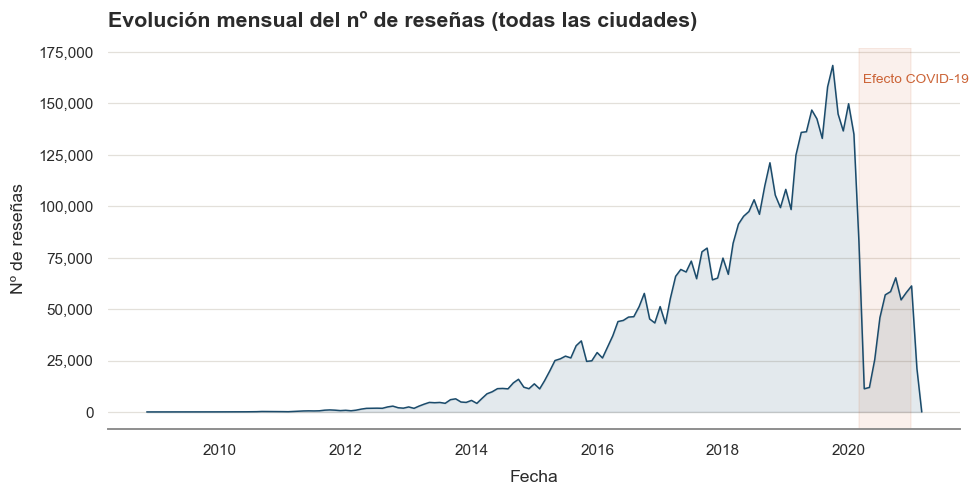

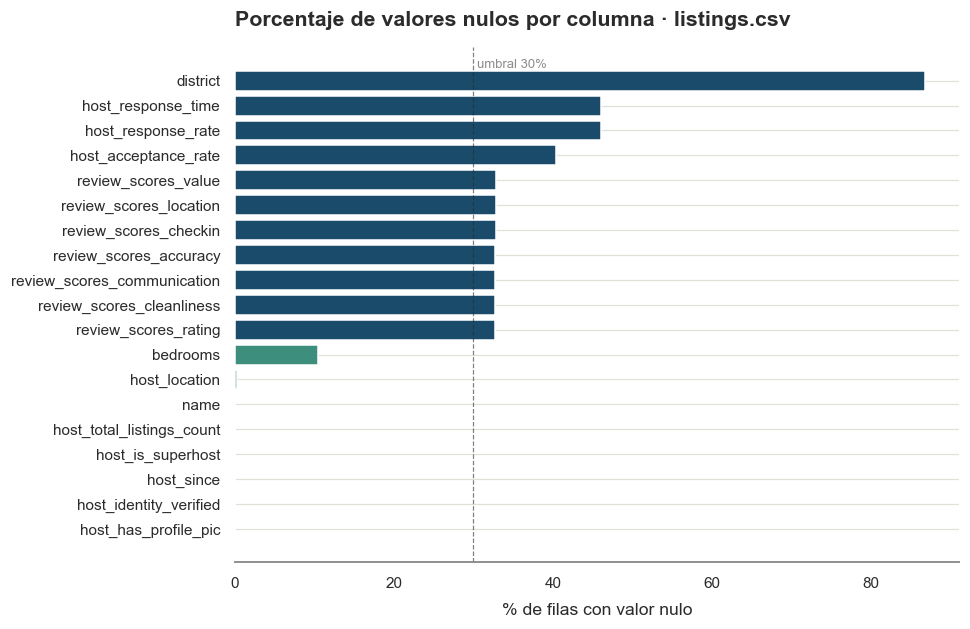

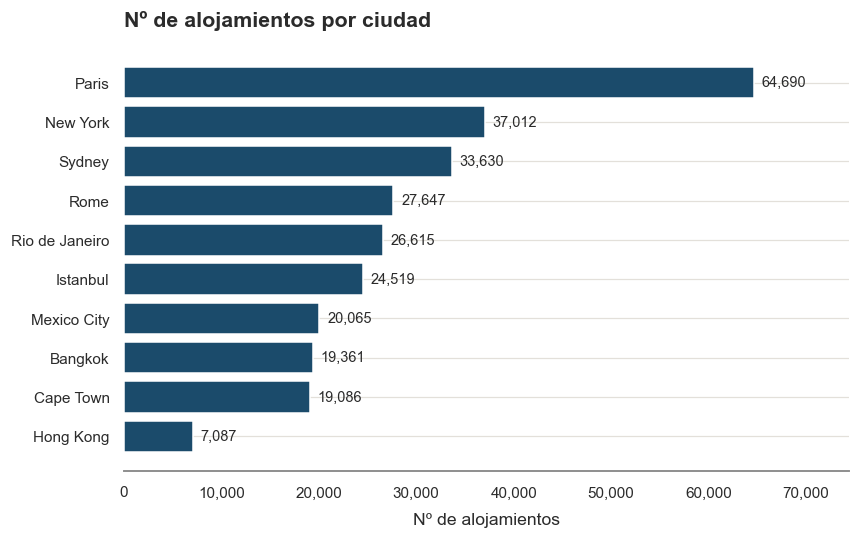

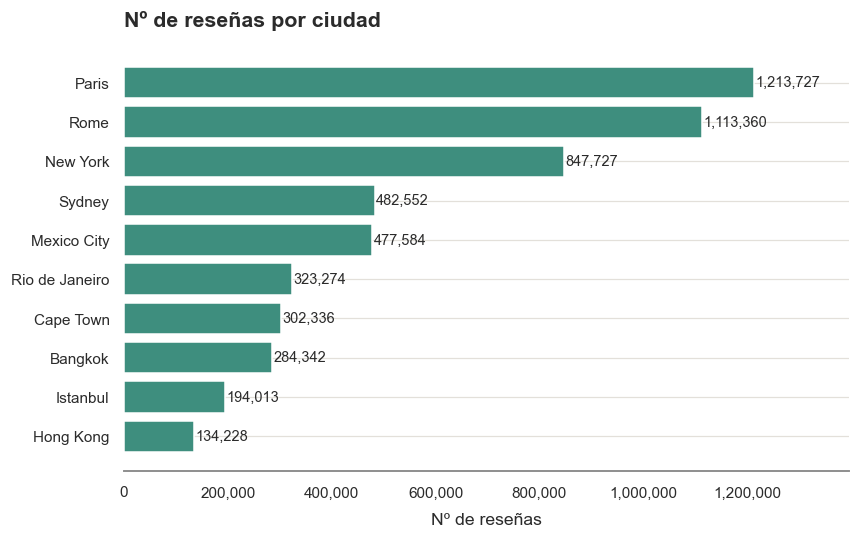

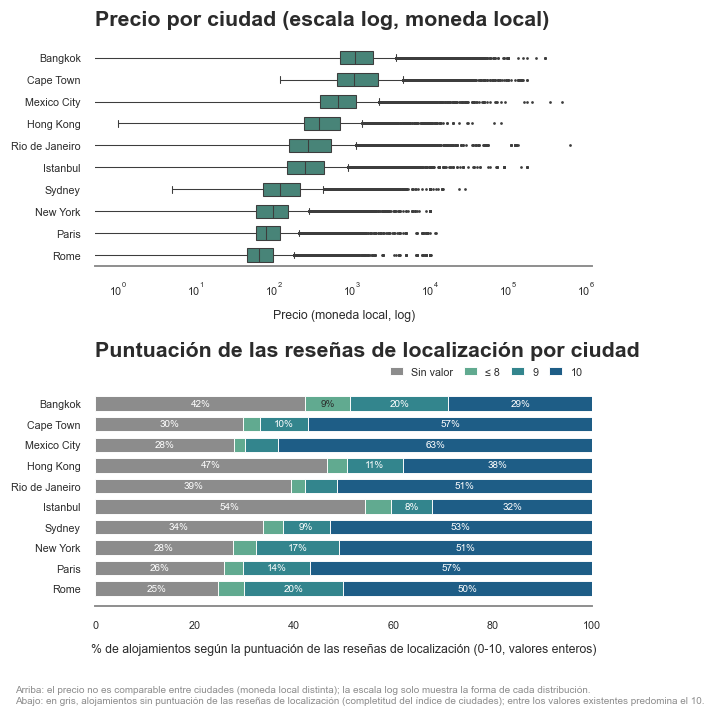

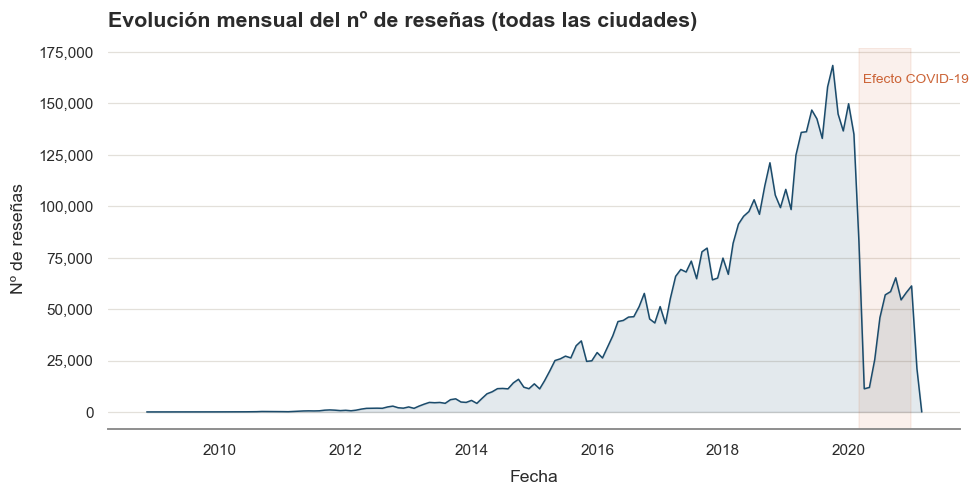

In [6]:
# Percentage of missing values per column
plot_missing_values(listings, "output/figures/f0a_missing_values.png")

# Volume of listings per city
plot_city_volume(listings, "output/figures/f0a_city_volume.png")

# Volume of reviews per city
plot_reviews_volume(listings, reviews, "output/figures/f0a_reviews_volume.png")

# Distribution of price and review scores (complete dataset)
plot_price_and_scores_distribution(listings, "output/figures/f0a_price_scores_dist.png")

# Temporal range and evolution of reviews
plot_reviews_timeline(reviews, "output/figures/f0a_reviews_timeline.png")


### City selection

Before the client chooses a city, an objective data-quality index is built per city, so the client is offered a Top 5 of candidates well supported by data instead of an arbitrary choice that could land on a city with poor data.

Quality index (0-100), weighted combination of:
  - 40% completeness of `review_scores_location` (key variable of the high-standing score; if it is missing in many listings, the score loses reliability)
  - 30% listings volume (more listings → more robust density clusters)
  - 30% reviews volume (more reviews → a more reliable, less noisy demand variable)

Volumes are MinMax-scaled 0-1 across cities; completeness enters as its raw share (0-1). The weights are a reasoned starting point, not tuned.

In [7]:
W_COMPLETENESS = 0.40
W_VOLUME_LISTINGS = 0.30
W_VOLUME_REVIEWS = 0.30
TOP_N_CITIES = 5

# Quality index per city (completeness + volume of listings + volume of reviews)
def build_city_quality_index(listings: pd.DataFrame, reviews: pd.DataFrame) -> pd.DataFrame:
    """Quality index (0-100) per city, used to choose the city to analyse:
      W_COMPLETENESS    * % of listings with review_scores_location
      W_VOLUME_LISTINGS * number of listings (MinMax-scaled across cities)
      W_VOLUME_REVIEWS  * number of reviews  (MinMax-scaled across cities)

    Returns one row per city, sorted by quality_index (descending).
    """
    by_city = listings.groupby("city").agg(
        n_listings=("listing_id", "count"),
        pct_location_score=("review_scores_location", lambda x: x.notna().mean() * 100),
    ).reset_index()

    rev_city = reviews.merge(listings[["listing_id", "city"]], on="listing_id", how="inner")
    n_reviews = rev_city.groupby("city").size().rename("n_reviews").reset_index()

    df = by_city.merge(n_reviews, on="city", how="left")
    df["n_reviews"] = df["n_reviews"].fillna(0)

    scaler = MinMaxScaler()
    df[["listings_n01", "reviews_n01"]] = scaler.fit_transform(df[["n_listings", "n_reviews"]])
    df["completeness_n01"] = df["pct_location_score"] / 100.0

    df["quality_index"] = (
        W_COMPLETENESS * df["completeness_n01"]
        + W_VOLUME_LISTINGS * df["listings_n01"]
        + W_VOLUME_REVIEWS * df["reviews_n01"]
    ) * 100

    return df.sort_values("quality_index", ascending=False).reset_index(drop=True)


# Plot city ranking based on quality index
def plot_city_ranking(df: pd.DataFrame, top_n: int = TOP_N_CITIES, save_path=None):
    """Horizontal bar chart of the city quality index."""
    d = df.sort_values("quality_index")
    colors = [PALETTE["primary"] if i >= len(d) - top_n else PALETTE["neutral_mid"]
              for i in range(len(d))]

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    bars = ax.barh(d["city"], d["quality_index"], color=colors)

    # Values targeted on the end of each bar (avoids having to read the axis with precision)
    for bar, val in zip(bars, d["quality_index"]):
        ax.text(val + 1, bar.get_y() + bar.get_height() / 2, f"{val:.0f}",
                va="center", fontsize=9.5, color=PALETTE["neutral_dark"])

    style_axis(
        ax,
        title="Índice de calidad de datos por ciudad",
        xlabel="Índice de calidad de datos (0-100)",
        ylabel=None,
    )
    ax.set_xlim(0, 100)
    if save_path:
        fig.savefig(save_path)
    


Ranking completo de ciudades candidatas:

          city  n_listings  pct_location_score  n_reviews  quality_index
         Paris       64690                74.2    1213727           89.7
          Rome       27647                75.3    1113360           68.0
      New York       37012                72.2     847727           64.3
        Sydney       33630                66.3     482552           50.0
   Mexico City       20065                72.0     477584           45.1
Rio de Janeiro       26615                60.5     323274           39.6
     Cape Town       19086                70.2     302336           39.0
       Bangkok       19361                57.7     284342           33.6
      Istanbul       24519                45.8     194013           29.0
     Hong Kong        7087                53.3     134228           21.3

Top 5 recomendado para presentar al cliente:
['Paris', 'Rome', 'New York', 'Sydney', 'Mexico City']


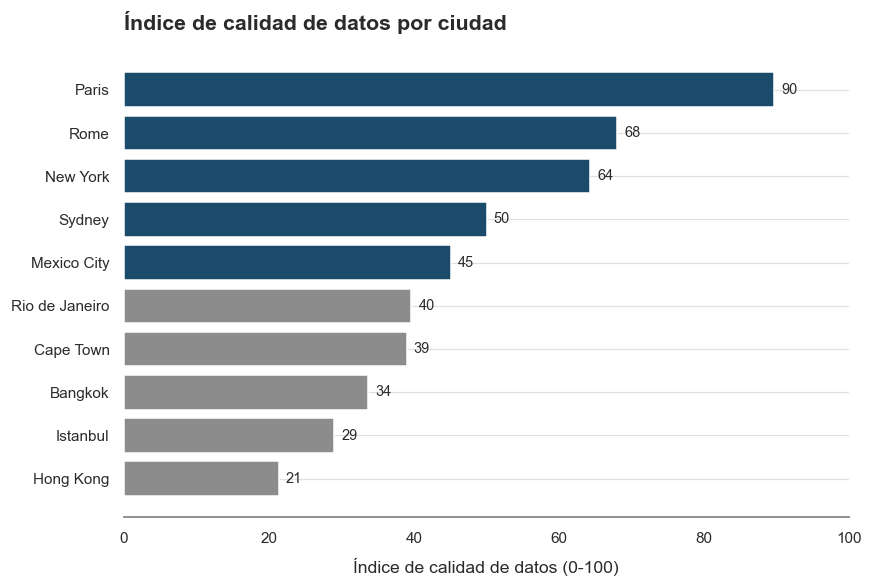

In [8]:
# Top N recommended cities for the client based on quality index
ranking = build_city_quality_index(listings, reviews)

print("Ranking completo de ciudades candidatas:\n")
print(ranking[["city", "n_listings", "pct_location_score", "n_reviews",
                "quality_index"]].round(1).to_string(index=False))

print(f"\nTop {TOP_N_CITIES} recomendado para presentar al cliente:")
print(ranking.head(TOP_N_CITIES)["city"].tolist())

#ranking.to_csv("output/city_quality_ranking.csv", index=False)
plot_city_ranking(ranking, save_path="output/figures/f0_city_ranking.png")

## Phase 1: ETL, high-standing score & shortlist
With the results delivered, the client chose **Paris** (the top-ranked city). This phase runs the ETL on the chosen city and computes the high-standing score (**70% scaled price + 30% scaled `review_scores_location`**).

It also builds the demand variable from `reviews.csv` and the shortlist of listings with `highstanding_score >= SCORE_THRESHOLD` (0.90).

**Design decisions:**
- All scaling is within the city: `price` is in local currency and its distribution differs a lot between cities, so scaling globally would mix currencies and bias the score towards expensive cities.
- Price outliers are trimmed at the 1st-99th percentile within the city before scaling.
- Listings without `price`, `review_scores_location` or coordinates are dropped, not imputed.
- Listings with `minimum_nights >= 30` are excluded: they are medium/long-term rentals, not the short-stay tourist profile relevant to a neighbourhood gourmet shop.
- Demand is computed over two windows: full history (`reviews_total`) and the last `RECENT_YEARS_WINDOW = 3` years excluding 2020 (`reviews_recent`), because the COVID drop does not reflect a structural change in demand. The recent window is the one used downstream.
- Many listings tie at score 1.0, so the shortlist is sorted by score, then `reviews_recent`, then `review_scores_rating`.

### Filtering the chosen city

The dataset description warns about inconsistent city spellings, but checking the actual data found exactly 10 clean `city` values, so a case-insensitive match on the city name is enough.

In [9]:
city = "Paris"

def filter_city(df: pd.DataFrame, city_name: str) -> pd.DataFrame:
    """Filter the dataset to a single city (case-insensitive, exact match)."""
    mask = df["city"].astype(str).str.strip().str.lower() == city_name.strip().lower()
    result = df[mask].copy()
    print(f"[fase0] Ciudad '{city_name}': {len(result):,} listings encontrados "
          f"({len(result) / len(df):.2%} del dataset completo).")
    print(f"Nº de barrios únicos en '{city_name}': {result['neighbourhood'].nunique()}")
    return result


listings_city = filter_city(listings, city)


[fase0] Ciudad 'Paris': 64,690 listings encontrados (23.13% del dataset completo).
Nº de barrios únicos en 'Paris': 20


### ETL, score and shortlist

In [10]:
RECENT_YEARS_WINDOW = 3   # most recent years of the dataset considered "current demand"
COVID_YEAR = 2020
PRICE_WEIGHT = 0.70
LOCATION_WEIGHT = 0.30
SCORE_THRESHOLD = 0.90 


# ---------------------------------------------------------------------------
# ETL
# ---------------------------------------------------------------------------
def clean_listings(df: pd.DataFrame) -> pd.DataFrame:
    """ 
    Cleans the listings DataFrame by removing nulls, filtering out non-turistic stays, 
    and handling price outliers.
    """
    df = df.copy()

    # Robust conversion of price to float, removing currency symbols and commas
    df["price"] = (
        df["price"].astype(str).str.replace(r"[^\d.]", "", regex=True).replace("", np.nan).astype(float)
    )
    for col in ["review_scores_location", "review_scores_rating",
                "review_scores_cleanliness", "review_scores_value"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    before = len(df)
    # Drop rows with critical nulls
    df = df.dropna(subset=["price", "review_scores_location", "latitude", "longitude"])
    # Long-term stays are not the target tourist profile
    df = df[df["minimum_nights"] < 30]
    # Exclude prices lower than or equal to 0 or extreme outliers (percentiles 1 and 99)
    p1, p99 = df["price"].quantile([0.01, 0.99])
    df = df[(df["price"] > 0) & (df["price"].between(p1, p99))]

    print(f"[phase1] ETL: {before:,} -> {len(df):,} listings tras limpieza "
          f"({before - len(df):,} descartados).")
    return df


def compute_demand(listings: pd.DataFrame, reviews: pd.DataFrame,
                    dataset_max_year: int | None = None) -> pd.DataFrame:
    """
    Add to listings 2 demand variables calculated from reviews.csv:
      - reviews_total: complete history (proxy for accumulated traction)
      - reviews_recent: last RECENT_YEARS_WINDOW years excluding COVID_YEAR
        (proxy for CURRENT demand, without the noise of the 2020 drop)
    """
    reviews = reviews.copy()
    reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
    reviews = reviews.dropna(subset=["date"])

    max_year = dataset_max_year or reviews["date"].dt.year.max()
    recent_start = max_year - RECENT_YEARS_WINDOW + 1

    total = reviews.groupby("listing_id").size().rename("reviews_total")

    recent_mask = (reviews["date"].dt.year >= recent_start) & (reviews["date"].dt.year != COVID_YEAR)
    recent = reviews[recent_mask].groupby("listing_id").size().rename("reviews_recent")

    out = listings.merge(total, on="listing_id", how="left") \
                   .merge(recent, on="listing_id", how="left")
    out[["reviews_total", "reviews_recent"]] = out[["reviews_total", "reviews_recent"]].fillna(0)
    print(f"[phase1] Demanda calculada. Ventana reciente: {recent_start}-{max_year} "
          f"(excluyendo {COVID_YEAR} por efecto COVID).")
    return out


# ---------------------------------------------------------------------------
# SCORE HIGH-STANDING (escalado intra-ciudad)
# ---------------------------------------------------------------------------
def compute_highstanding_score(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculus of the high-standing score = 0.7*price_scaled + 0.3*location_scaled.
    MinMax scaling is performed within the received subset (assumes df is already filtered to a single city -> phase 0).
    """
    df = df.copy()
    scaler = MinMaxScaler()
    df[["price_scaled", "location_scaled"]] = scaler.fit_transform(
        df[["price", "review_scores_location"]]
    )
    df["highstanding_score"] = (
        PRICE_WEIGHT * df["price_scaled"] + LOCATION_WEIGHT * df["location_scaled"]
    )
    return df


def get_shortlist(df: pd.DataFrame, threshold: float = SCORE_THRESHOLD) -> pd.DataFrame:
    """Listings with highstanding_score >= threshold, ranked by score (ties broken by
    recent reviews and overall rating). Keeps only the descriptive columns and
    uses a 1-based 'rank' index.
    """
    cols = ["listing_id", "name", "neighbourhood", "latitude", "longitude",
            "price", "review_scores_location", "review_scores_rating",
            "reviews_total", "reviews_recent",
            "price_scaled", "location_scaled", "highstanding_score"]
    cols = [c for c in cols if c in df.columns]
    sort_cols = [c for c in ["highstanding_score", "reviews_recent", "review_scores_rating"]
                 if c in df.columns]
    shortlist = df[df["highstanding_score"] >= threshold].sort_values(
        sort_cols, ascending=False)[cols].reset_index(drop=True)
    shortlist.index += 1
    shortlist.index.name = "rank"
    print(f"[phase1] Shortlist (score >= {threshold}): {len(shortlist):,} listings "
          f"({len(shortlist) / len(df):.2%} del dataset limpio).")
    return shortlist


def run_phase1(listings_city: pd.DataFrame, reviews: pd.DataFrame, threshold: float = SCORE_THRESHOLD):
    """Runs the full phase 1 pipeline and returns (df_scored, shortlist)."""
    df = clean_listings(listings_city)
    df = compute_demand(df, reviews)
    df = compute_highstanding_score(df)
    shortlist = get_shortlist(df, threshold)
    return df, shortlist


In [11]:
df_scored, shortlist = run_phase1(listings_city, reviews)

[phase1] ETL: 64,690 -> 45,787 listings tras limpieza (18,903 descartados).
[phase1] Demanda calculada. Ventana reciente: 2019-2021 (excluyendo 2020 por efecto COVID).
[phase1] Shortlist (score >= 0.9): 195 listings (0.43% del dataset limpio).


### Visualization

Charts generated (all used in the report):
  1. Shortlist composition by neighbourhood: count + average score (bar, sorted)
  2. Geographic scatter of the shortlist over the full dataset
  3. Demand (recent reviews) by neighbourhood, aggregated over the shortlist

/var/folders/qt/1c6hwf2j3b94fvm7wmnbpy580000gn/T/ipykernel_10630/2857231452.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap(SEQUENTIAL_CMAP)(norm(agg["avg_score"]))


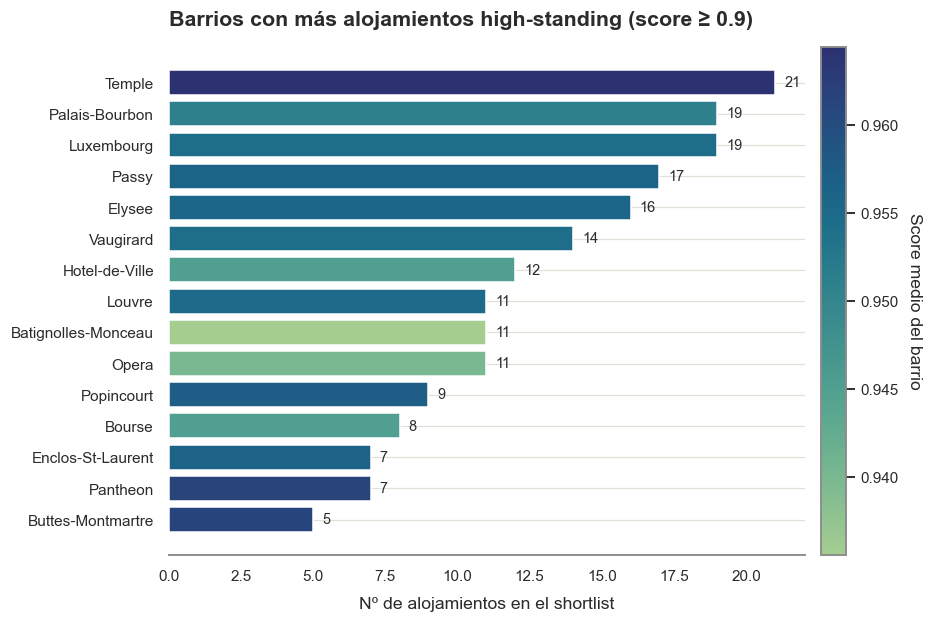

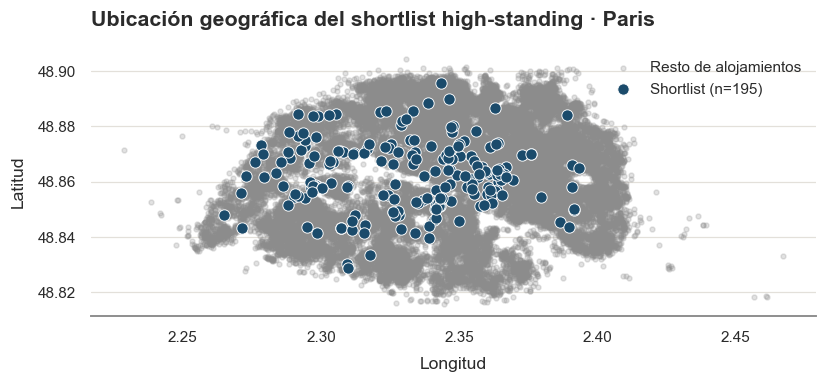

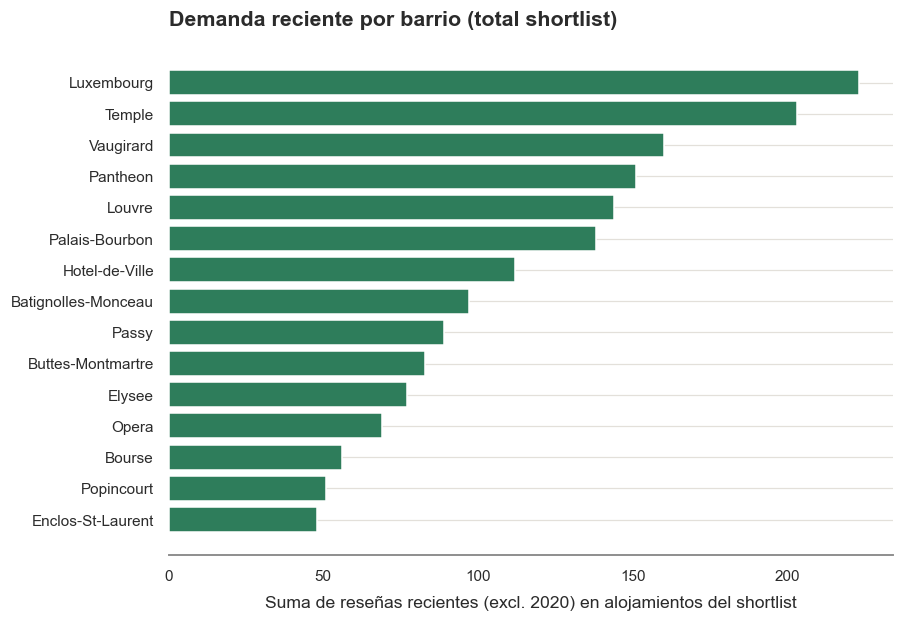

In [12]:
def plot_shortlist_by_neighbourhood(shortlist: pd.DataFrame, score_threshold: float,
                                     top_n_neighbourhoods=15, save_path=None):
    """
    Neighbourhood-level summary of the shortlist: count of shortlisted
    listings (bar length) and average score (color).
    """
    agg = (shortlist.groupby("neighbourhood")
           .agg(n_listings=("listing_id", "count"),
                avg_score=("highstanding_score", "mean"))
           .sort_values("n_listings", ascending=False)
           .head(top_n_neighbourhoods)
           .sort_values("n_listings"))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(agg))))
    norm = plt.Normalize(agg["avg_score"].min(), agg["avg_score"].max())
    colors = plt.cm.get_cmap(SEQUENTIAL_CMAP)(norm(agg["avg_score"]))
    bars = ax.barh(agg.index, agg["n_listings"], color=colors)

    for bar, n in zip(bars, agg["n_listings"]):
        ax.text(n + max(agg["n_listings"]) * 0.015, bar.get_y() + bar.get_height() / 2,
                str(n), va="center", fontsize=9.5, color=PALETTE["neutral_dark"])

    sm = plt.cm.ScalarMappable(cmap=SEQUENTIAL_CMAP, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Score medio del barrio", rotation=270, labelpad=15)

    style_axis(
        ax,
        title=f"Barrios con más alojamientos high-standing (score ≥ {score_threshold})",
        xlabel="Nº de alojamientos en el shortlist",
        ylabel=None,
    )
    if save_path:
        fig.savefig(save_path)
    return fig


def plot_geographic_shortlist(df: pd.DataFrame, shortlist_ids, city: str, save_path=None):
    """Geographic scatter: all listings in light grey, shortlist highlighted."""
    fig, ax = plt.subplots(figsize=(8.5, 8))

    ax.scatter(df["longitude"], df["latitude"], s=10, alpha=0.25,
               color=PALETTE["neutral_mid"], label="Resto de alojamientos")

    shortlist_pts = df[df["listing_id"].isin(shortlist_ids)]
    ax.scatter(shortlist_pts["longitude"], shortlist_pts["latitude"], s=55,
               color=PALETTE["primary"], edgecolor="white", linewidth=0.6,
               label=f"Shortlist (n={len(shortlist_pts)})", zorder=3)

    ax.set_aspect("equal")
    style_axis(
        ax,
        title=f"Ubicación geográfica del shortlist high-standing · {city}",
        xlabel="Longitud",
        ylabel="Latitud",
    )
    ax.legend(frameon=False, loc="best")
    if save_path:
        fig.savefig(save_path)
    return fig


def plot_demand_by_neighbourhood(shortlist: pd.DataFrame, top_n_neighbourhoods=15, save_path=None):
    """
    Aggregated recent demand (sum of reviews_recent) by neighbourhood,
    over the shortlist.
    """
    agg = (shortlist.groupby("neighbourhood")["reviews_recent"]
           .sum().sort_values(ascending=False).head(top_n_neighbourhoods).sort_values())

    fig, ax = plt.subplots(figsize=(8.5, max(4, 0.4 * len(agg))))
    ax.barh(agg.index, agg.values, color=PALETTE["accent"])

    style_axis(
        ax,
        title="Demanda reciente por barrio (total shortlist)",
        xlabel=f"Suma de reseñas recientes (excl. {2020}) en alojamientos del shortlist",
        ylabel=None,
        thousands_x=True,
    )
    if save_path:
        fig.savefig(save_path)
    return fig


shortlist_ids = shortlist["listing_id"].tolist()

plot_shortlist_by_neighbourhood(shortlist, SCORE_THRESHOLD, save_path="output/figures/f1_shortlist_by_neighbourhood.png")
plot_geographic_shortlist(df_scored, shortlist_ids, city, "output/figures/f1_geographic_shortlist.png")
plot_demand_by_neighbourhood(shortlist, save_path="output/figures/f1_demand_by_neighbourhood.png");


## Phase 2: Geospatial clustering
Geospatial clustering runs on all clean listings of the city from Phase 1 (`df_scored`), not only the shortlist: ~195 listings are too few for density clustering, and the goal is to see how the whole market groups together to find **candidate zones**, not individual flats.

Two algorithms are compared as a methodological contrast:
  - **DBSCAN**: fixed *eps* (constant neighbourhood radius). Assumes roughly homogeneous density; *eps* and *min_samples* must be set by hand.
  - **HDBSCAN**: variable density (hierarchical). No fixed *eps*, only *min_cluster_size* -- more robust in cities with a dense centre and a sparser periphery (the typical urban case).

Both use haversine distance on coordinates in radians (true geodesic distance on the sphere), NOT Euclidean distance on lat/lon degrees, which distorts distances depending on latitude.

In [13]:
EARTH_RADIUS_M = 6_371_000


# ---------------------------------------------------------------------------
# Coordinates conversion (grades to radians)
# ---------------------------------------------------------------------------
def to_radians(df: pd.DataFrame) -> np.ndarray:
    return np.radians(df[["latitude", "longitude"]].values)


# ---------------------------------------------------------------------------
# DBSCAN
# ---------------------------------------------------------------------------
def run_dbscan(df: pd.DataFrame, eps_meters: float = 200, min_samples: int = 20) -> pd.DataFrame:
    """
    DBSCAN uses haversine metric. 
    - eps_meters is the maximum distance between two points to be considered neighbors (in meters).
    - min_samples is the minimum number of points required to form a dense region (cluster).
    
    The function returns a DataFrame with an additional column 'cluster_dbscan' indicating the cluster label for each listing. 
    Noise points are labeled as -1.
    """
    coords_rad = to_radians(df)
    eps_rad = eps_meters / EARTH_RADIUS_M

    model = DBSCAN(eps=eps_rad, min_samples=min_samples, metric="haversine", algorithm="ball_tree")
    labels = model.fit_predict(coords_rad)

    out = df.copy()
    out["cluster_dbscan"] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    print(f"[DBSCAN] eps={eps_meters}m, min_samples={min_samples} -> "
          f"{n_clusters} clusters, {noise_pct:.1f}% ruido ({(labels == -1).sum():,} listings)")
    return out


# ---------------------------------------------------------------------------
# HDBSCAN
# ---------------------------------------------------------------------------
def run_hdbscan(df: pd.DataFrame, min_cluster_size: int = 25, min_samples: int = 10) -> pd.DataFrame:
    """HDBSCAN with haversine metric. 
    
    Returns a DataFrame with an additional column 'cluster_hdbscan' indicating the cluster label 
    for each listing. Noise points are labeled as -1.
    """
    coords_rad = to_radians(df)

    model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples,
                     metric="haversine")
    labels = model.fit_predict(coords_rad)

    out = df.copy()
    out["cluster_hdbscan"] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    print(f"[HDBSCAN] min_cluster_size={min_cluster_size}, min_samples={min_samples} -> "
          f"{n_clusters} clusters, {noise_pct:.1f}% ruido ({(labels == -1).sum():,} listings)")
    return out


# ---------------------------------------------------------------------------
# Cluster metrics
# ---------------------------------------------------------------------------
def cluster_metrics(df: pd.DataFrame, cluster_col: str) -> pd.DataFrame:
    """Aggregates listings into one row per cluster (noise, label -1, excluded):
    size, median price, mean location score, mean high-standing score, recent and
    total reviews, and centroid (mean lat/lon).

    cluster_col selects the labelling ('cluster_dbscan' or 'cluster_hdbscan').
    Returns the clusters sorted by highstanding_score_mean (descending).
    """
    valid = df[df[cluster_col] != -1]  # Exclude cluster noise points (-1) from the metrics calculation

    metrics = valid.groupby(cluster_col).agg(
        n_listings=("listing_id", "count"),
        price_median=("price", "median"),
        location_score_mean=("review_scores_location", "mean"),
        highstanding_score_mean=("highstanding_score", "mean"),
        reviews_recent_total=("reviews_recent", "sum"),
        reviews_total_total=("reviews_total", "sum"),
        centroid_lat=("latitude", "mean"),
        centroid_lon=("longitude", "mean"),
    ).reset_index()

    metrics = metrics.round({c: 2 for c in metrics.columns if not c.startswith("centroid_")})

    metrics = metrics.sort_values("highstanding_score_mean", ascending=False).reset_index(drop=True)
    return metrics


def compare_algorithms(df_dbscan: pd.DataFrame, df_hdbscan: pd.DataFrame) -> pd.DataFrame:
    """Side-by-side summary of DBSCAN vs HDBSCAN: number of clusters, % of noise,
    and median / max cluster size. One row per algorithm.
    """
    def _summary(labels, name):
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        sizes = pd.Series(labels[labels != -1]).value_counts()
        return {
            "algoritmo": name,
            "n_clusters": n_clusters,
            "pct_ruido": round(noise_pct, 1),
            "tamano_cluster_mediano": int(sizes.median()) if len(sizes) else 0,
            "tamano_cluster_max": int(sizes.max()) if len(sizes) else 0,
        }

    rows = [
        _summary(df_dbscan["cluster_dbscan"].values, "DBSCAN"),
        _summary(df_hdbscan["cluster_hdbscan"].values, "HDBSCAN"),
    ]
    return pd.DataFrame(rows)


In [14]:
# Sweep over different parameters for DBSCAN and HDBSCAN to find the best clustering configuration
dbscan_results = []
for eps in [30, 100, 200]:
    for min_samples in [10, 15, 20]:
        df_dbscan = run_dbscan(df_scored, eps_meters=eps, min_samples=min_samples)
        metrics = cluster_metrics(df_dbscan, "cluster_dbscan")
        dbscan_results.append({
            "eps_meters": eps,
            "min_samples": min_samples,
            "n_clusters": len(metrics),
            "pct_ruido": (df_dbscan["cluster_dbscan"] == -1).mean() * 100,
            "pct_cluster_mayoritario": (metrics["n_listings"].max() / len(df_dbscan)) * 100 if len(metrics) else 0
        })
hdbscan_results = []
for min_cluster_size in [25, 50]:
    for min_samples in [10,15,20]:
        df_hdbscan = run_hdbscan(df_scored, min_cluster_size=min_cluster_size, min_samples=min_samples)
        metrics = cluster_metrics(df_hdbscan, "cluster_hdbscan")
        hdbscan_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "n_clusters": len(metrics),
            "pct_ruido": (df_hdbscan["cluster_hdbscan"] == -1).mean() * 100,
            "pct_cluster_mayoritario": (metrics["n_listings"].max() / len(df_hdbscan)) * 100 if len(metrics) else 0
        })
print("\nDBSCAN results:")
print(pd.DataFrame(dbscan_results).sort_values(["n_clusters", "pct_ruido"]))
print("\nHDBSCAN results:")
print(pd.DataFrame(hdbscan_results).sort_values(["n_clusters", "pct_ruido"]))

[DBSCAN] eps=30m, min_samples=10 -> 349 clusters, 84.8% ruido (38,835 listings)
[DBSCAN] eps=30m, min_samples=15 -> 50 clusters, 97.4% ruido (44,596 listings)
[DBSCAN] eps=30m, min_samples=20 -> 14 clusters, 99.1% ruido (45,394 listings)
[DBSCAN] eps=100m, min_samples=10 -> 31 clusters, 3.5% ruido (1,607 listings)
[DBSCAN] eps=100m, min_samples=15 -> 67 clusters, 7.3% ruido (3,354 listings)
[DBSCAN] eps=100m, min_samples=20 -> 89 clusters, 14.3% ruido (6,554 listings)
[DBSCAN] eps=200m, min_samples=10 -> 2 clusters, 0.4% ruido (197 listings)
[DBSCAN] eps=200m, min_samples=15 -> 2 clusters, 0.6% ruido (281 listings)
[DBSCAN] eps=200m, min_samples=20 -> 2 clusters, 0.8% ruido (352 listings)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


[HDBSCAN] min_cluster_size=25, min_samples=10 -> 200 clusters, 45.5% ruido (20,821 listings)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


[HDBSCAN] min_cluster_size=25, min_samples=15 -> 147 clusters, 48.5% ruido (22,225 listings)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


... (3 outputs left out)

/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


[HDBSCAN] min_cluster_size=50, min_samples=15 -> 80 clusters, 45.7% ruido (20,921 listings)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


[HDBSCAN] min_cluster_size=50, min_samples=20 -> 9 clusters, 7.3% ruido (3,330 listings)

DBSCAN results:
   eps_meters  min_samples  n_clusters  pct_ruido  pct_cluster_mayoritario
6         200           10           2   0.430253                99.539171
7         200           15           2   0.613711                99.349160
8         200           20           2   0.768777                99.143862
2          30           20          14  99.141678                 0.163802
3         100           10          31   3.509730                87.837159
1          30           15          50  97.398825                 0.196562
4         100           15          67   7.325223                63.186057
5         100           20          89  14.314107                60.248542
0          30           10         349  84.816651                 0.993732

HDBSCAN results:
   min_cluster_size  min_samples  n_clusters  pct_ruido  \
5                50           20           9   7.272807   
3       

Results of the parameter sweep:

* DBSCAN
    - Larger *eps* → almost everything merges into one macro-cluster.
    - Small *eps* → almost everything is scattered noise.

    → Compromise: `eps=100m`; between `min_samples` 15 and 20, 15 is chosen for its lower noise (7.3%). Even so, one macro-cluster holds 68% of the clustered listings (chaining effect).

* HDBSCAN
    - The same macro-cluster appears with a high `min_cluster_size`.
    - More diversified clusters come with a high share of noise.

    → Compromise between (50, 15) and (25, 10): with similar noise (~45.5%), (25, 10) is chosen for its finer granularity (200 zones vs 80). HDBSCAN is the method used downstream (`cluster_hdbscan`).

In [15]:
df_dbscan = run_dbscan(df_scored, eps_meters=100, min_samples=15)
df_hdbscan = run_hdbscan(df_scored, min_cluster_size=25, min_samples=10)

[DBSCAN] eps=100m, min_samples=15 -> 67 clusters, 7.3% ruido (3,354 listings)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


[HDBSCAN] min_cluster_size=25, min_samples=10 -> 200 clusters, 45.5% ruido (20,821 listings)


In [16]:
print("\nComparativa de algoritmos:")
print(compare_algorithms(df_dbscan, df_hdbscan).to_string(index=False))

print("\nTop 5 clusters DBSCAN por highstanding_score_mean:")
metrics_db = cluster_metrics(df_dbscan, "cluster_dbscan")
print(metrics_db.head().to_string(index=False))

print("\nTop 5 clusters HDBSCAN por highstanding_score_mean:")
metrics_hdb = cluster_metrics(df_hdbscan, "cluster_hdbscan")
print(metrics_hdb.head().to_string(index=False))


Comparativa de algoritmos:
algoritmo  n_clusters  pct_ruido  tamano_cluster_mediano  tamano_cluster_max
   DBSCAN          67        7.3                      33               28931
  HDBSCAN         200       45.5                      54                2551

Top 5 clusters DBSCAN por highstanding_score_mean:
 cluster_dbscan  n_listings  price_median  location_score_mean  highstanding_score_mean  reviews_recent_total  reviews_total_total  centroid_lat  centroid_lon
             43          25         179.0                 9.96                     0.54                 137.0                  344     48.868805      2.302384
             54          23         117.0                10.00                     0.52                 428.0                  964     48.866917      2.325851
             58          16         151.0                 9.81                     0.51                 262.0                  465     48.883815      2.298087
             39         176         119.0            

### Visualization

Phase 2 figures (geospatial clustering):
  1. Scatter map: DBSCAN clusters (evidence of the chaining effect)
  2. Scatter map: HDBSCAN clusters (chosen method)
  3. Cluster size distribution, DBSCAN vs HDBSCAN

In [17]:
def _cluster_color_map(labels):
    """Assigns a color to each cluster label, with noise (-1) in gray. Returns a dictionary mapping label -> color."""
    uniq = sorted(set(labels) - {-1})
    colors = get_categorical_palette(len(uniq)) if uniq else []
    cmap = {c: colors[i] for i, c in enumerate(uniq)}
    cmap[-1] = PALETTE["noise"]
    return cmap


def plot_clusters_map(df: pd.DataFrame, cluster_col: str, city: str, title_suffix="", save_path=None):
    """Display the clusters on a geographic scatter plot, with noise points in light gray and clusters colored distinctly."""
    cmap = _cluster_color_map(df[cluster_col].values)
    is_noise = df[cluster_col] == -1

    lon_range = df["longitude"].max() - df["longitude"].min()
    lat_range = df["latitude"].max() - df["latitude"].min()
    width = 9.0
    height = np.clip(width * (lat_range / lon_range), 4.0, 9.0)

    fig, ax = plt.subplots(figsize=(width, height))

    ax.scatter(df.loc[is_noise, "longitude"], df.loc[is_noise, "latitude"],
               s=6, alpha=0.25, color=PALETTE["noise"], zorder=1)

    non_noise = df[~is_noise]
    colors = non_noise[cluster_col].map(cmap)
    ax.scatter(non_noise["longitude"], non_noise["latitude"],
               s=8, alpha=0.55, c=colors, zorder=2)

    n_clusters = len(cmap) - 1
    ax.set_aspect("equal")
    style_axis(
        ax,
        title=f"Clusters geoespaciales · {city} ({n_clusters} zonas){title_suffix}",
        xlabel="Longitud", ylabel="Latitud",
    )
    ax.scatter([], [], s=30, color=PALETTE["noise"], label="Ruido (sin cluster)")
    ax.scatter([], [], s=30, color=PALETTE["primary"], label="Clusters")
    ax.legend(frameon=False, loc="best")
    if n_clusters > 9:
        fig.text(0.01, -0.02,
                  f"Con {n_clusters} zonas, el color solo distingue clusters entre sí "
                  "(no sigue la paleta de marca; imposible con tantas categorías distinguibles).",
                  fontsize=8.5, color=PALETTE["neutral_mid"])
        fig.subplots_adjust(bottom=0.1)
    if save_path:
        fig.savefig(save_path)
    return fig


def plot_cluster_size_comparison(df_dbscan: pd.DataFrame, df_hdbscan: pd.DataFrame, save_path=None):
    """Two bar charts with the sizes of the 15 largest clusters of DBSCAN and HDBSCAN,
    annotated with the share of clustered listings held by the largest cluster
    (shows whether one cluster absorbs most of the city).
    """
    sizes_db = df_dbscan[df_dbscan["cluster_dbscan"] != -1]["cluster_dbscan"].value_counts().sort_values(ascending=False)
    sizes_hdb = df_hdbscan[df_hdbscan["cluster_hdbscan"] != -1]["cluster_hdbscan"].value_counts().sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    top_db = sizes_db.head(15)
    axes[0].bar(range(len(top_db)), top_db.values, color=PALETTE["primary"])
    pct_top1 = sizes_db.iloc[0] / sizes_db.sum() * 100
    axes[0].text(0.5, 0.92, f"El cluster #1 concentra el {pct_top1:.0f}% de los alojamientos clusterizados",
                 transform=axes[0].transAxes, ha="center", fontsize=9.5, color=PALETTE["alert"])
    style_axis(axes[0], title="DBSCAN · tamaño de los 15 clusters mayores",
               xlabel="Cluster (ordenado por tamaño)", ylabel="Nº de alojamientos", thousands_y=True)

    top_hdb = sizes_hdb.head(15)
    axes[1].bar(range(len(top_hdb)), top_hdb.values, color=PALETTE["accent"])
    pct_top1_h = sizes_hdb.iloc[0] / sizes_hdb.sum() * 100
    axes[1].text(0.5, 0.92, f"El cluster #1 concentra el {pct_top1_h:.0f}% de los alojamientos clusterizados",
                 transform=axes[1].transAxes, ha="center", fontsize=9.5, color=PALETTE["neutral_mid"])
    style_axis(axes[1], title="HDBSCAN · tamaño de los 15 clusters mayores",
               xlabel="Cluster (ordenado por tamaño)", ylabel="Nº de alojamientos", thousands_y=True)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    return fig


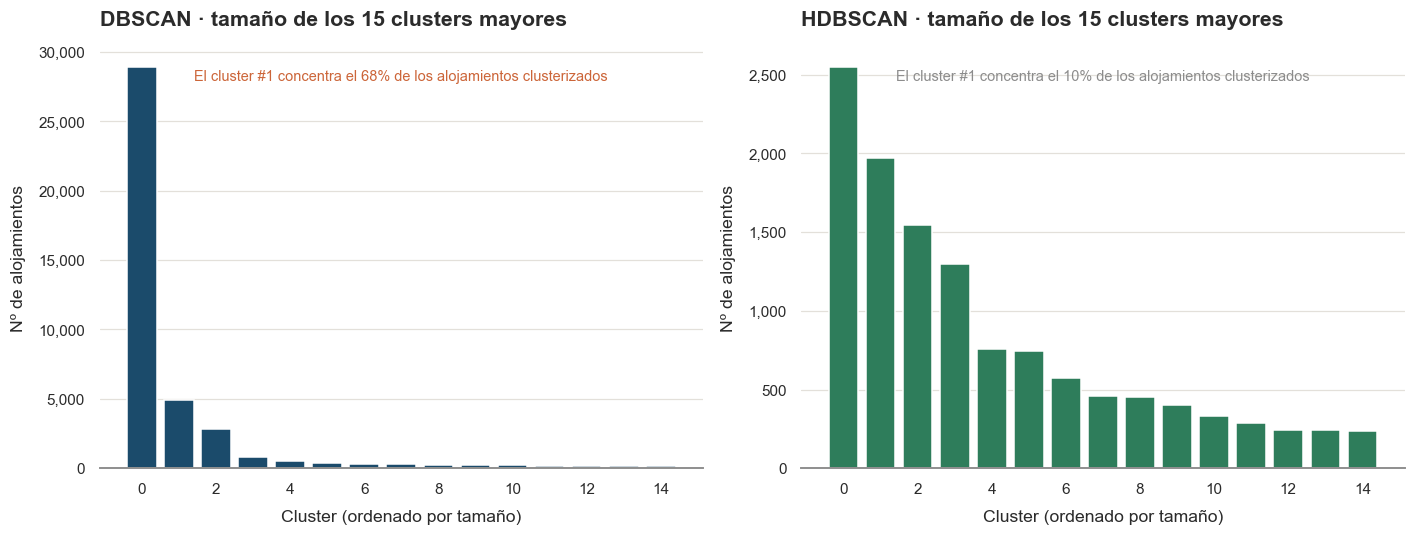

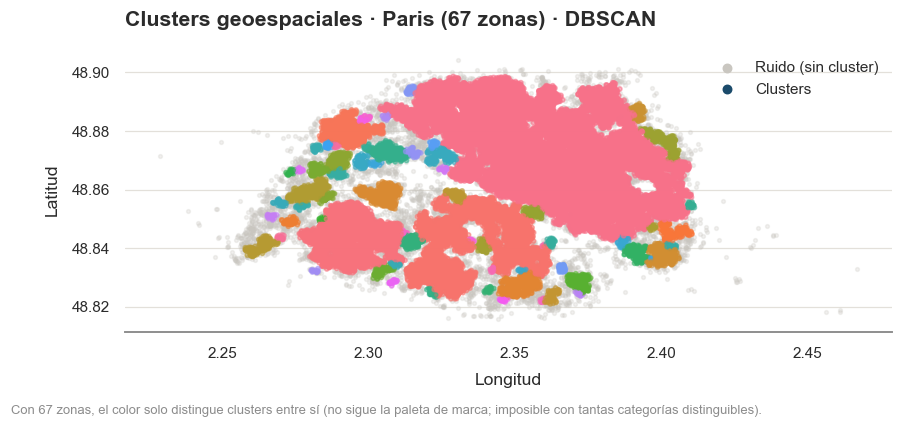

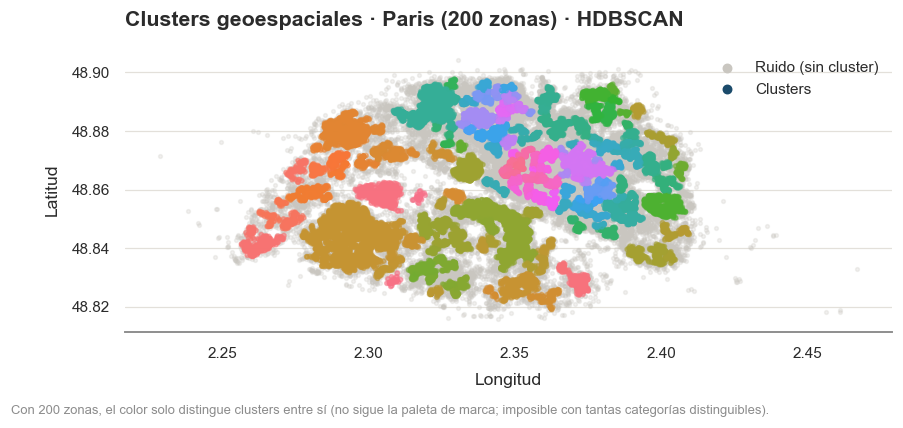

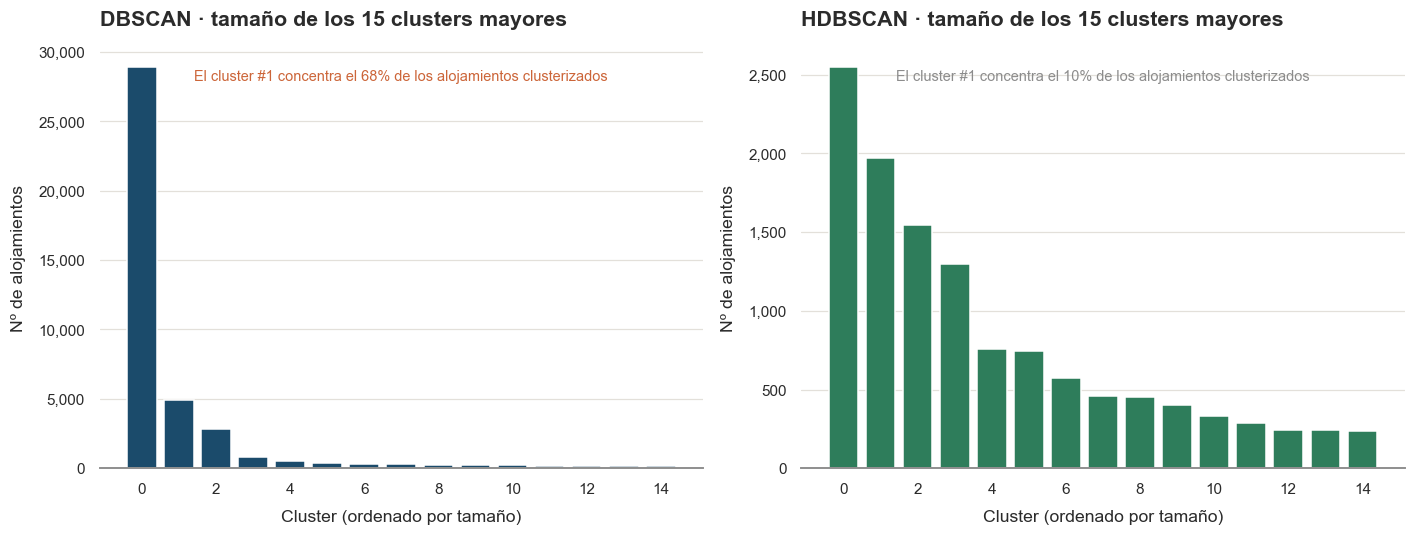

In [18]:
plot_clusters_map(df_dbscan, "cluster_dbscan", city,
                    " · DBSCAN", "output/figures/f2_map_dbscan.png")
plot_clusters_map(df_hdbscan, "cluster_hdbscan", city,
                    " · HDBSCAN", "output/figures/f2_map_hdbscan.png")
plot_cluster_size_comparison(df_dbscan, df_hdbscan, "output/figures/f2_size_comparison.png")

## Phase 3: Enrichment with open data (OSM + INSEE)

### OSM

Phase 3: enrichment with open data from OpenStreetMap (Overpass API).

  - Gourmet competitors: delicatessen, cheese, chocolate, confectionery,
    wine and butcher shops (gourmet retail only, no restaurants) -- to compute the cannibalization index per zone.
  - Accessibility: train/metro stations, bus stops, parking -- to compute
    the distance to the nearest transit point per zone.

**City bounding box.** All queries to external sources (Overpass here, INSEE Filosofi below) are restricted to
the city's *bounding box*: the smallest latitude/longitude rectangle (south, west, north, east) that contains
every clean listing of the city (`df_scored`), widened by a margin of 0.01° on each side (~1.1 km in latitude,
~0.7 km in longitude at Paris' latitude) so that competitors, transit points and income cells just outside the
outermost listings are not lost. It is derived from the data itself (`city_bbox_from_listings`), not from an
administrative boundary; for Paris it covers roughly 12 × 19 km. A single query per bounding box (instead of one
per zone) keeps the number of API calls minimal.

Competition is measured in a 400 m walking catchment around each zone centroid: cannibalization index = gourmet competitors / clean listings, both counted within that radius. A shop near several zones counts for all of them. Accessibility is the distance from the zone centroid to the nearest transit point.

In [19]:
OVERPASS_URL = "https://overpass-api.de/api/interpreter"
OVERPASS_HEADERS = {"User-Agent": "TFM-Geomarketing-Gourmet/1.0 (academic use)"}
CACHE_DIR = "cache_osm"
EARTH_RADIUS_M = 6_371_000
COMPETITION_RADIUS_M = 400  # walking catchment around each zone centroid (DECISIONS.md D21)

# OSM tags for competitors: gourmet RETAIL only. Restaurants are excluded, since the
# client's business is take-away retail, not dining (DECISIONS.md D37)
COMPETITOR_TAGS = {
    "shop=deli": "Delicatessen",
    "shop=cheese": "Quesería",
    "shop=chocolate": "Chocolatería",
    "shop=confectionery": "Confitería",
    "shop=wine": "Vinoteca",
    "shop=butcher": "Carnicería gourmet",
}

# OSM tags for accessibility/transport
ACCESSIBILITY_TAGS = {
    "railway=station": "Estación de tren/metro",
    "station=subway": "Metro",
    "highway=bus_stop": "Parada de bus",
    "amenity=parking": "Aparcamiento",
}


# ---------------------------------------------------------------------------
# Overpass API queries
# ---------------------------------------------------------------------------
def _overpass_query_for_bbox(bbox, tag_dict):
    """Builds an Overpass QL query for multiple tags within a bounding box."""
    south, west, north, east = bbox
    clauses = []
    for tag in tag_dict:
        k, v = tag.split("=")
        clauses.append(f'node["{k}"="{v}"]({south},{west},{north},{east});')
        clauses.append(f'way["{k}"="{v}"]({south},{west},{north},{east});')
    body = "\n".join(clauses)
    return f"[out:json][timeout:90];\n(\n{body}\n);\nout center;"


def fetch_osm_pois(bbox, tag_dict, cache_name, use_cache=True, max_retries=3):
    """
    Downloads POIs from OSM within a bounding box for a set of
    tags, with caching on disk.
    """
    os.makedirs(CACHE_DIR, exist_ok=True)
    cache_path = os.path.join(CACHE_DIR, f"{cache_name}.json")

    if use_cache and os.path.exists(cache_path):
        with open(cache_path) as f:
            data = json.load(f)
        print(f"[OSM] Cargado desde caché: {cache_path} ({len(data.get('elements', [])):,} elementos)")
        return data

    query = _overpass_query_for_bbox(bbox, tag_dict)
    for attempt in range(1, max_retries + 1):
        try:
            resp = requests.post(OVERPASS_URL, data={"data": query},
                                  headers=OVERPASS_HEADERS, timeout=120)
            resp.raise_for_status()
            data = resp.json()
            with open(cache_path, "w") as f:
                json.dump(data, f)
            print(f"[OSM] Descargados {len(data.get('elements', [])):,} elementos -> {cache_path}")
            return data
        except requests.exceptions.RequestException as e:
            wait = 5 * attempt
            print(f"[OSM] Intento {attempt}/{max_retries} fallido ({e}); reintentando en {wait}s...")
            time.sleep(wait)
    raise RuntimeError(f"No se pudo consultar Overpass tras {max_retries} intentos.")


def osm_response_to_df(osm_json, tag_dict):
    """Converts the OSM JSON response to a pandas DataFrame."""
    tag_lookup = {tuple(t.split("=")): label for t, label in tag_dict.items()}
    rows = []
    for el in osm_json.get("elements", []):
        lat = el.get("lat") or (el.get("center") or {}).get("lat")
        lon = el.get("lon") or (el.get("center") or {}).get("lon")
        if lat is None or lon is None:
            continue
        tags = el.get("tags", {})
        category = next((label for (k, v), label in tag_lookup.items() if tags.get(k) == v), None)
        if category is None:  # element from a cached query with tags no longer in tag_dict
            continue
        rows.append({
            "osm_id": el.get("id"), "name": tags.get("name", "(sin nombre)"),
            "category": category, "latitude": lat, "longitude": lon,
        })
    return pd.DataFrame(rows).drop_duplicates(subset="osm_id").reset_index(drop=True)


# ---------------------------------------------------------------------------
# Spatial join: POIs around zone centroids
# ---------------------------------------------------------------------------
def haversine_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a))


def count_points_within(points_df, centroids_df, radius_m):
    """
    Number of points (latitude/longitude columns) within radius_m of each
    centroid (centroid_lat/centroid_lon columns). A point counts for every
    centroid it is close to, not only the nearest one: a shop competes with
    all zones within walking distance, wherever the cluster borders fall.
    """
    if points_df.empty:
        return np.zeros(len(centroids_df), dtype=int)
    dists = haversine_m(centroids_df["centroid_lat"].values[:, None],
                        centroids_df["centroid_lon"].values[:, None],
                        points_df["latitude"].values[None, :],
                        points_df["longitude"].values[None, :])
    return (dists <= radius_m).sum(axis=1)


# ---------------------------------------------------------------------------
# Business metrics per cluster
# ---------------------------------------------------------------------------
def compute_competition_metrics(competitors_df, listings_df, cluster_metrics_df,
                                radius_m=COMPETITION_RADIUS_M):
    """
    Cannibalization index = gourmet competitors / clean listings, both
    counted within radius_m of the zone centroid. Numerator and denominator
    share the same catchment, so the index measures competition relative to
    the local tourist market and does not depend on how far the HDBSCAN
    cluster extends. Higher = more saturated (worse for a new opening).
    """
    out = cluster_metrics_df.copy()
    out["n_competitors"] = count_points_within(competitors_df, out, radius_m)
    out["n_listings_catchment"] = count_points_within(listings_df, out, radius_m)
    out["cannibalization_index"] = (
        out["n_competitors"] / out["n_listings_catchment"].clip(lower=1)).round(4)
    return out


def compute_accessibility_metrics(accessibility_df, cluster_metrics_df):
    """Distance from each cluster's centroid to the nearest transit point."""
    out = cluster_metrics_df.copy()
    if accessibility_df.empty:
        out["dist_to_transit_m"] = np.nan
        return out
    dists = [
        haversine_m(row["centroid_lat"], row["centroid_lon"],
                    accessibility_df["latitude"].values, accessibility_df["longitude"].values).min()
        for _, row in cluster_metrics_df.iterrows()
    ]
    out["dist_to_transit_m"] = np.round(dists, 1)
    return out


def enrich_cluster_metrics(cluster_metrics_df, competitors_df, accessibility_df, listings_df):
    """Full pipeline: computes the competition and accessibility metrics on cluster_metrics_df."""
    out = compute_competition_metrics(competitors_df, listings_df, cluster_metrics_df)
    return compute_accessibility_metrics(accessibility_df, out)


def city_bbox_from_listings(df_scored, margin=0.01):
    """Bounding box (south, west, north, east) derived from the listings themselves."""
    return (
        df_scored["latitude"].min() - margin, df_scored["longitude"].min() - margin,
        df_scored["latitude"].max() + margin, df_scored["longitude"].max() + margin,
    )


In [20]:
# City bounding box derived from the data itself (with margin)
bbox = city_bbox_from_listings(df_scored)

osm_competitors_raw = fetch_osm_pois(bbox, COMPETITOR_TAGS, cache_name=f"{city}_competitors")
osm_accessibility_raw = fetch_osm_pois(bbox, ACCESSIBILITY_TAGS, cache_name=f"{city}_accessibility")

competitors_df = osm_response_to_df(osm_competitors_raw, COMPETITOR_TAGS)
accessibility_df = osm_response_to_df(osm_accessibility_raw, ACCESSIBILITY_TAGS)

enriched_metrics = enrich_cluster_metrics(
    metrics_hdb, competitors_df, accessibility_df, listings_df=df_scored)

print(enriched_metrics.sort_values("cannibalization_index").head(10).to_string(index=False))
enriched_metrics.to_csv("output/paris_cluster_metrics_enriched.csv", index=False)

[OSM] Cargado desde caché: cache_osm/Paris_competitors.json (13,583 elementos)
[OSM] Cargado desde caché: cache_osm/Paris_accessibility.json (11,785 elementos)
 cluster_hdbscan  n_listings  price_median  location_score_mean  highstanding_score_mean  reviews_recent_total  reviews_total_total  centroid_lat  centroid_lon  n_competitors  n_listings_catchment  cannibalization_index  dist_to_transit_m
              15          49          94.0                 9.96                     0.44                 706.0                 1747     48.857005      2.285506              1                   170                 0.0059               58.7
             178          29          95.0                10.00                     0.41                 280.0                  887     48.866641      2.359116              6                   996                 0.0060              117.6
              52          38          66.5                 9.32                     0.35                 327.0             

### OSM visualization

Phase 3 figures (OSM enrichment: competition and accessibility):
  1. Zone ranking by cannibalization index (lower = better)
  2. Zone ranking by distance to the nearest transit point (accessibility)

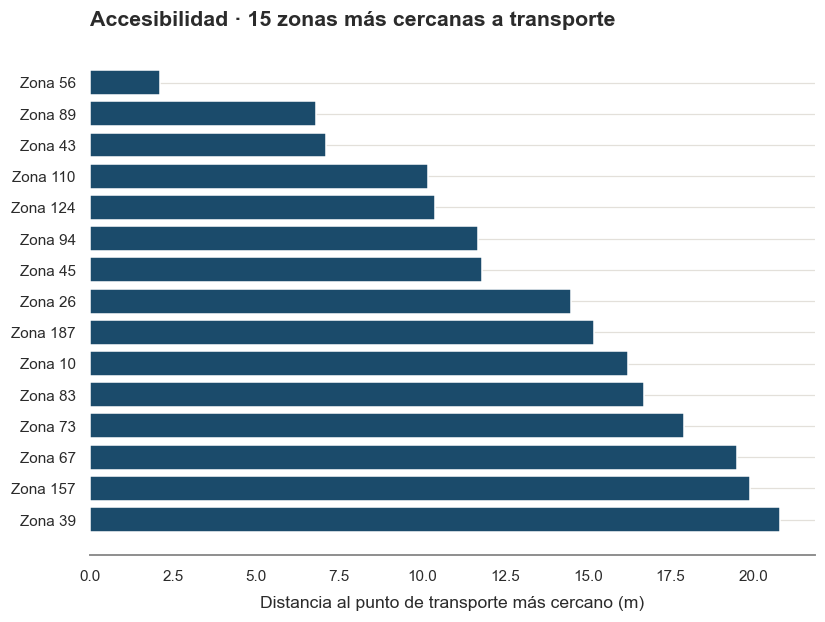

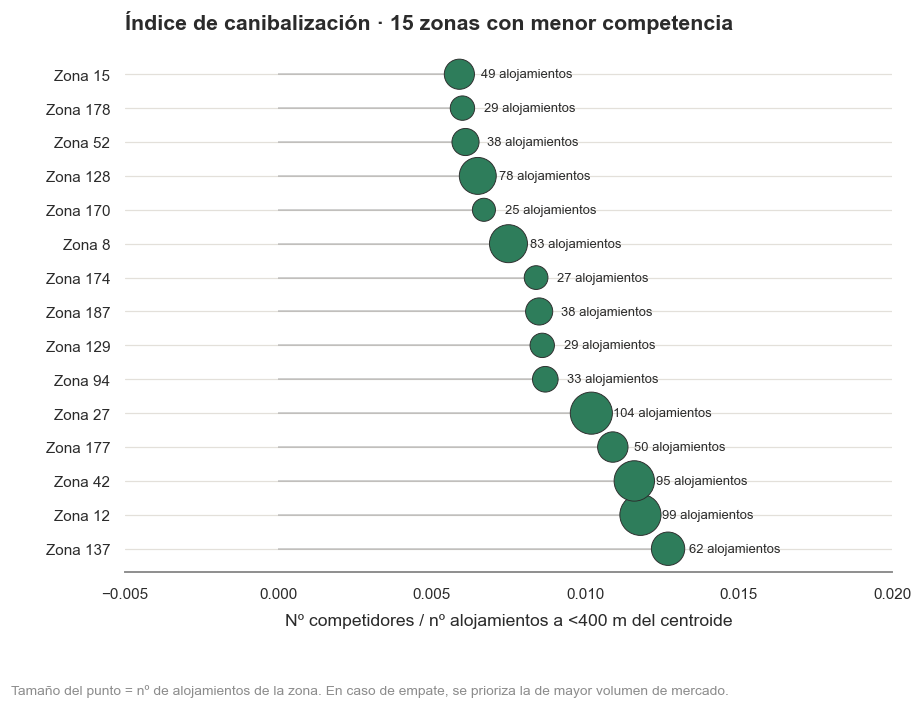

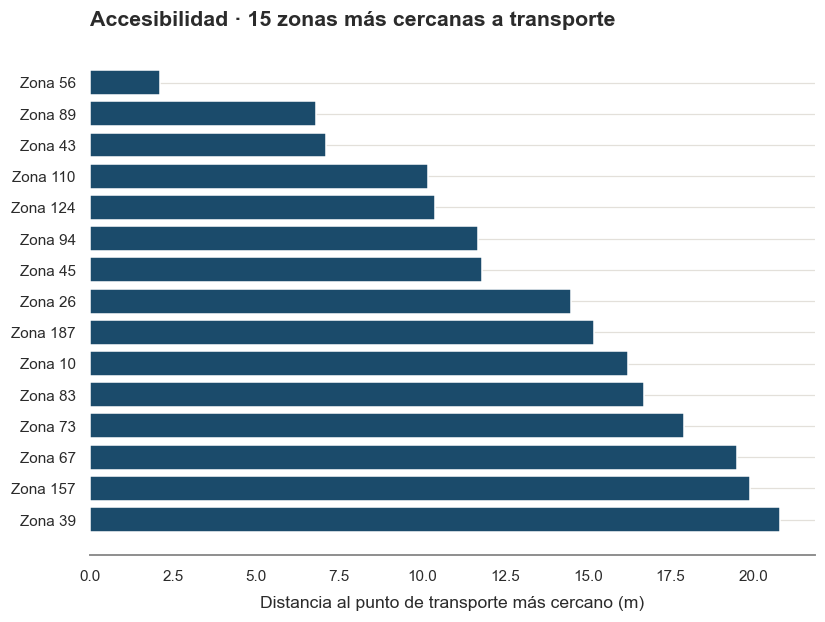

In [21]:
def plot_cannibalization_ranking(enriched_metrics: pd.DataFrame, cluster_id_col: str,
                                  top_n=15, save_path=None):
    """
    Zones with the LOWEST relative competition first (best candidates).
    Lollipop chart: position = cannibalization index, point SIZE = number
    of listings in the zone (market volume); ties are broken by the larger
    market.
    """
    d = enriched_metrics.sort_values(["cannibalization_index", "n_listings"],
                                      ascending=[True, False]).head(top_n)
    d = d.sort_values("cannibalization_index", ascending=False).reset_index(drop=True)
    labels = [f"Zona {c}" for c in d[cluster_id_col]]

    fig, ax = plt.subplots(figsize=(9, 6.5))
    sizes = (d["n_listings"] / d["n_listings"].max()) * 700 + 60

    ax.hlines(y=labels, xmin=0, xmax=d["cannibalization_index"],
              color=PALETTE["neutral_mid"], linewidth=1, alpha=0.5, zorder=1)
    ax.scatter(d["cannibalization_index"], labels, s=sizes, color=PALETTE["accent"],
               edgecolor=PALETTE["neutral_dark"], linewidth=0.6, zorder=2)

    for y, (_, row) in enumerate(d.iterrows()):
        ax.annotate(f"{int(row['n_listings'])} alojamientos",
                    xy=(row["cannibalization_index"], y), xytext=(14, 0),
                    textcoords="offset points", va="center", fontsize=8.5,
                    color=PALETTE["neutral_dark"])

    style_axis(
        ax,
        title=f"Índice de canibalización · {top_n} zonas con menor competencia",
        xlabel="Nº competidores / nº alojamientos a <400 m del centroide",
        ylabel=None,
    )
    ax.set_xlim(-0.005, max(d["cannibalization_index"].max() * 1.3, 0.02))
    fig.text(0.01, -0.02,
              "Tamaño del punto = nº de alojamientos de la zona. En caso de empate, "
              "se prioriza la de mayor volumen de mercado.",
              fontsize=9, color=PALETTE["neutral_mid"])
    fig.subplots_adjust(bottom=0.15)
    if save_path:
        fig.savefig(save_path)
    return fig


def plot_accessibility_ranking(enriched_metrics: pd.DataFrame, cluster_id_col: str,
                                top_n=15, save_path=None):
    """Most accessible zones (shortest distance to transit) first."""
    d = enriched_metrics.nsmallest(top_n, "dist_to_transit_m").sort_values(
        "dist_to_transit_m", ascending=False)
    labels = [f"Zona {c}" for c in d[cluster_id_col]]

    fig, ax = plt.subplots(figsize=(8.5, 6))
    ax.barh(labels, d["dist_to_transit_m"], color=PALETTE["primary"])

    style_axis(
        ax,
        title=f"Accesibilidad · {top_n} zonas más cercanas a transporte",
        xlabel="Distancia al punto de transporte más cercano (m)",
        ylabel=None,
    )
    if save_path:
        fig.savefig(save_path)
    return fig


enriched = pd.read_csv("output/paris_cluster_metrics_enriched.csv")

plot_cannibalization_ranking(enriched, "cluster_hdbscan", save_path="output/figures/f3_cannibalization.png")
plot_accessibility_ranking(enriched, "cluster_hdbscan", save_path="output/figures/f3_accessibility.png")


### INSEE

Phase 3 (part 2): enrichment with mean income per zone, using INSEE Filosofi gridded data (200m cells). 

#### Extra dependencies

    pip install pyproj          # Filosofi uses EPSG:3035 (metric)
    pip install duckdb          # reads the remote parquet
    pip install pyarrow         # parquet read/write (on-disk cache)

The cells inside the city bounding box are cached in `cache_insee/` (see `fetch_filosofi`), so data.gouv.fr is only queried once per city.

#### Data source
INSEE Filosofi gridded data (200m cells, metropolitan France), via data.gouv.fr, parquet format, EPSG:3035. The notebook uses the **2019** vintage, which matches the recent demand window (mostly 2019):

- Dataset page: https://www.data.gouv.fr/datasets/revenus-pauvrete-et-niveau-de-vie-donnees-carroyees-2019-et-2021-dispositif-fichier-localise-social-et-fiscal-filosofi
- 2019 (used, 154.7 MB): https://www.data.gouv.fr/api/1/datasets/r/b480cead-3f46-4b1b-a943-62a009b83f7a
- 2021 (90.5 MB): https://www.data.gouv.fr/api/1/datasets/r/55432374-a91d-43d0-923d-4514dc3eb951
- Official schema documentation: https://www.insee.fr/fr/statistiques/fichier/8735106/documentation_donnees-carroyees_filosofi2021.pdf

#### Schema (verified against the official INSEE documentation)

    idcar_200m : cell id, format "CRS3035RES200mN<y>E<x>", where <y>,<x> are the EPSG:3035 coordinates in METRES of the cell's south-west corner.
    ind        : number of individuals (population) in the cell
    men        : number of fiscal households
    ind_snv    : SUM (not mean, not median) of the winsorized standard of living of the cell's individuals -- mean income per capita must be computed as ind_snv / ind; it is not provided directly.
    i_est_200  : 1 if the cell's value is IMPUTED (aggregated with neighbouring cells because it did not reach the confidentiality threshold of 11 fiscal households). Relevant: ~78-79% of all French cells are imputed (source: official documentation).

#### Important methodological limitation (document in the report)
Filosofi at 200m does NOT publish MEDIAN income (statistical confidentiality); only a MEAN per cell can be derived (ind_snv/ind). It is used here as a proxy for neighbourhood purchasing power, not as a true median.

Cells within 300 m of each zone centroid are averaged into `income_proxy`; the number of cells and the share imputed are kept as a confidence indicator per zone.

In [22]:
#!pip install pyproj
#!pip install duckdb

In [23]:
FILOSOFI_URL = "https://www.data.gouv.fr/api/1/datasets/r/b480cead-3f46-4b1b-a943-62a009b83f7a"  # 2019 vintage
FILOSOFI_CACHE_DIR = "cache_insee"


def parse_idcar_200m(idcar: str):
    """Extract (x_sw, y_sw) in meters EPSG:3035 from 'CRS3035RES200mN<y>E<x>'."""
    m = re.search(r"N(\d+)E(\d+)", idcar)
    y_sw, x_sw = int(m.group(1)), int(m.group(2))
    return x_sw, y_sw


def fetch_filosofi(bbox_latlon, cache_name: str, url: str = FILOSOFI_URL,
                   use_cache: bool = True) -> pd.DataFrame:
    """
    Downloads the Filosofi cells inside the city bounding box via duckdb.
    The filtered cells are cached on disk (parquet) so data.gouv.fr is only
    hit once per city (the full national file is ~150 MB).
    """
    cache_path = os.path.join(FILOSOFI_CACHE_DIR, f"{cache_name}.parquet")
    if use_cache and os.path.exists(cache_path):
        df = pd.read_parquet(cache_path)
        print(f"[INSEE] Loaded from cache: {cache_path} ({len(df):,} cells)")
        return df

    to_3035 = Transformer.from_crs("EPSG:4326", "EPSG:3035", always_xy=True)
    south, west, north, east = bbox_latlon
    x_min, y_min = to_3035.transform(west, south)
    x_max, y_max = to_3035.transform(east, north)

    con = duckdb.connect()
    df = con.execute(f"SELECT * FROM read_parquet('{url}')").df()

    x_sw, y_sw = zip(*df["idcar_200m"].apply(parse_idcar_200m))
    x_sw, y_sw = np.array(x_sw), np.array(y_sw)
    df = df[(x_sw >= x_min) & (x_sw <= x_max) & (y_sw >= y_min) & (y_sw <= y_max)]

    os.makedirs(FILOSOFI_CACHE_DIR, exist_ok=True)
    df.to_parquet(cache_path, index=False)
    print(f"[INSEE] {len(df):,} cells inside the city bounding box -> {cache_path}")
    return df


def add_cell_centroid_latlon(df: pd.DataFrame) -> pd.DataFrame:
    """Add latitude/longitude (centroid of the cell) from idcar_200m."""
    to_4326 = Transformer.from_crs("EPSG:3035", "EPSG:4326", always_xy=True)
    df = df.copy()
    x_sw, y_sw = zip(*df["idcar_200m"].apply(parse_idcar_200m))
    x_center, y_center = np.array(x_sw) + 100, np.array(y_sw) + 100  # +100m = mitad del lado
    lon, lat = to_4326.transform(x_center, y_center)
    df["latitude"], df["longitude"] = lat, lon
    return df


def compute_income_proxy(df: pd.DataFrame) -> pd.DataFrame:
    """
    Compute income proxy for each cell.
    """
    df = df.copy()
    df = df[df["ind"] > 0]
    df["income_proxy"] = df["ind_snv"] / df["ind"]
    df["is_imputed"] = df["i_est_200"].astype(bool)
    return df


def assign_income_to_clusters(income_df: pd.DataFrame, cluster_centroids_df: pd.DataFrame,
                               max_distance_m: float = 300) -> pd.DataFrame:
    """Assign to each cluster the average income proxy of the nearby Filosofi cells."""
    rows = []
    for _, row in cluster_centroids_df.iterrows():
        dists = haversine_m(row["centroid_lat"], row["centroid_lon"],
                             income_df["latitude"].values, income_df["longitude"].values)
        nearby = income_df[dists <= max_distance_m]
        rows.append({
            "cluster_id": row["cluster_id"],
            "income_proxy": nearby["income_proxy"].mean() if len(nearby) else np.nan,
            "income_pct_imputed": nearby["is_imputed"].mean() * 100 if len(nearby) else np.nan,
            "n_filosofi_cells": len(nearby),
        })
    return pd.DataFrame(rows)

In [24]:
#!pip install pyarrow

In [25]:
bbox = city_bbox_from_listings(df_scored)

raw = fetch_filosofi(bbox, cache_name=f"{city}_filosofi_2019")
raw = add_cell_centroid_latlon(raw)
income_df = compute_income_proxy(raw)

centroids = metrics_hdb[["cluster_hdbscan", "centroid_lat", "centroid_lon"]].rename(
    columns={"cluster_hdbscan": "cluster_id"})
income_by_cluster = assign_income_to_clusters(income_df, centroids)

# Combina las 4 dimensiones de la fase 3 en un único DataFrame: score
# (fase 1-2) + canibalización/accesibilidad (OSM, celda anterior) + renta (INSEE)
enriched = enriched_metrics.merge(income_by_cluster, left_on="cluster_hdbscan",
                                   right_on="cluster_id", how="left")
enriched.to_csv("output/paris_cluster_metrics_income.csv", index=False)

print(enriched[["cluster_hdbscan", "n_listings", "income_proxy", "income_pct_imputed"]]
      .head(10).to_string(index=False))

[INSEE] Loaded from cache: cache_insee/Paris_filosofi_2019.parquet (4,091 cells)
 cluster_hdbscan  n_listings  income_proxy  income_pct_imputed
             168          28  43560.796124                 0.0
              17          83  43995.244694                 0.0
              10          26  50938.548002                 0.0
              25          86  47313.157504                 0.0
              47         453  43107.403796                 0.0
              26          26  48824.176682                 0.0
              20         166  44024.035008                 0.0
              22          89  48450.325747                 0.0
              54         106  43403.288550                 0.0
              49         138  47195.974617                 0.0


### INSEE visualization

Phase 3 figure (income): zone ranking by income proxy, flagging zones with a high share of imputed Filosofi cells.

Figures saved to output/figures/


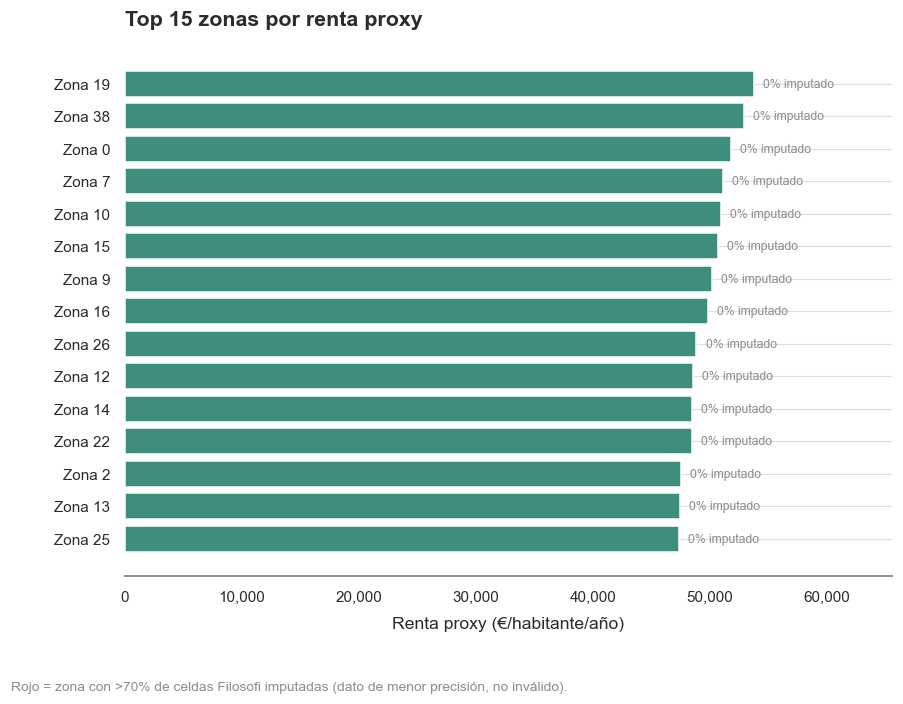

In [26]:
def plot_income_ranking(enriched: pd.DataFrame, cluster_id_col: str, top_n=15, save_path=None):
    """
    Top N zones by income proxy, with the % of imputed cells as a
    reliability flag (Filosofi imputes ~78-79% of French cells for
    statistical secrecy -- a high % does not invalidate the value, but
    calls for caution).
    """
    d = enriched.dropna(subset=["income_proxy"]).nlargest(top_n, "income_proxy").sort_values("income_proxy")
    labels = [f"Zona {c}" for c in d[cluster_id_col]]

    fig, ax = plt.subplots(figsize=(9, 6.5))
    colors = [PALETTE["alert"] if p > 70 else PALETTE["secondary"] for p in d["income_pct_imputed"]]
    ax.barh(labels, d["income_proxy"], color=colors)

    for y, (_, row) in enumerate(d.iterrows()):
        ax.annotate(f"{row['income_pct_imputed']:.0f}% imputado", xy=(row["income_proxy"], y),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=PALETTE["neutral_mid"])

    style_axis(ax, title=f"Top {top_n} zonas por renta proxy",
               xlabel="Renta proxy (€/habitante/año)", ylabel=None, thousands_x=True)
    ax.set_xlim(0, d["income_proxy"].max() * 1.22)
    fig.text(0.01, -0.02,
              "Rojo = zona con >70% de celdas Filosofi imputadas (dato de menor precisión, no inválido).",
              fontsize=9, color=PALETTE["neutral_mid"])
    fig.subplots_adjust(bottom=0.14)
    if save_path:
        fig.savefig(save_path)
    return fig



plot_income_ranking(enriched, "cluster_hdbscan", save_path="output/figures/f3b_income_ranking.png")

print("Figures saved to output/figures/")

## Phase 4: Opportunity index, geocoding and dashboard

### Part 1: opportunity index
Opportunity index per zone (0-100), combining 5 dimensions built in Phases 1-3:

| Dimension | Variable | Direction | Default weight |
|---|---|---|---|
| High-standing score (Phases 1-2) | `highstanding_score_mean` | higher is better | 0.30 |
| Cannibalization (Phase 3, OSM) | `cannibalization_index` | lower is better | 0.25 |
| Accessibility (Phase 3, OSM) | `dist_to_transit_m` | lower is better | 0.15 |
| Income (Phase 3, INSEE) | `income_proxy` | higher is better | 0.15 |
| Demand (Phases 1-2) | `demand_per_listing` | higher is better | 0.15 |

Design decisions:
  - All five components are MinMax-scaled 0-1 before weighting, so none dominates by its natural scale (€/year, index, metres, reviews). Missing values are filled with the median and the row is flagged (`is_complete`).
  - Cannibalization and distance are inverted (`1 - scaled`) so that a higher component always means "better for the client".
  - Demand is the only signal of observed behaviour (the other four are structural). It is measured per listing (`reviews_recent_total / n_listings`), because total reviews mechanically rewarded the largest zones.
  - The weights are a reasoned starting point, not statistically tuned: there is no ground-truth "correct opportunity" to fit them to. The index **ranks** zones; it is not a sales forecast. The client can change the weights in the dashboard.

In [27]:
DEFAULT_WEIGHTS = {
    "score": 0.30,
    "cannibalization": 0.25,
    "accessibility": 0.15,
    "income": 0.15,
    "demand": 0.15,
}
 
 
def build_opportunity_index(enriched: pd.DataFrame, weights: dict = None) -> pd.DataFrame:
    """
    Computes the opportunity index (0-100) per zone. `enriched` must
    contain: highstanding_score_mean, cannibalization_index,
    dist_to_transit_m, income_proxy, and (n_listings, reviews_recent_total)
    if `weights` includes a "demand" key (the default). Rows missing any
    required column (e.g. no Filosofi cell nearby) are kept but flagged,
    not silently dropped -- see `is_complete` column.
    """
    weights = weights or DEFAULT_WEIGHTS
    assert abs(sum(weights.values()) - 1.0) < 1e-6, "Weights must sum to 1.0"
 
    df = enriched.copy()
    df["demand_per_listing"] = df["reviews_recent_total"] / df["n_listings"]

    required = ["highstanding_score_mean", "cannibalization_index",
                "dist_to_transit_m", "income_proxy", "demand_per_listing"]
    df["is_complete"] = df[required].notna().all(axis=1)
 
    scaler = MinMaxScaler()
    scaled = pd.DataFrame(
        scaler.fit_transform(df[required].fillna(df[required].median())),
        columns=[f"{c}_scaled" for c in required], index=df.index,
    )
    df = pd.concat([df, scaled], axis=1)
 
    score = (
        weights["score"] * df["highstanding_score_mean_scaled"]
        + weights["cannibalization"] * (1 - df["cannibalization_index_scaled"])
        + weights["accessibility"] * (1 - df["dist_to_transit_m_scaled"])
        + weights["income"] * df["income_proxy_scaled"]
        + weights["demand"] * df["demand_per_listing_scaled"]
    )

    df["opportunity_index"] = 100 * score
    return df.sort_values("opportunity_index", ascending=False).reset_index(drop=True)
 


In [28]:
enriched = pd.read_csv("output/paris_cluster_metrics_enriched.csv")
income = pd.read_csv("output/paris_cluster_metrics_income.csv")

full = enriched.merge(
        income[["cluster_hdbscan", "income_proxy", "income_pct_imputed", "n_filosofi_cells"]],
        on="cluster_hdbscan", how="left"
    )

ranked = build_opportunity_index(full)
print(f"Zonas rankeadas: {len(ranked)} ({ranked['is_complete'].sum()} con las 5 dimensiones disponibles)")
print(ranked[["cluster_hdbscan", "n_listings", "highstanding_score_mean",
                  "cannibalization_index", "dist_to_transit_m", "income_proxy",
                  "demand_per_listing", "opportunity_index"]].head(10).round(2).to_string(index=False))

ranked.to_csv("output/paris_opportunity_index.csv", index=False)

Zonas rankeadas: 200 (200 con las 5 dimensiones disponibles)
 cluster_hdbscan  n_listings  highstanding_score_mean  cannibalization_index  dist_to_transit_m  income_proxy  demand_per_listing  opportunity_index
             168          28                     0.53                   0.01               84.5      43560.80                9.14              80.77
              15          49                     0.44                   0.01               58.7      50699.82               14.41              79.57
              20         166                     0.47                   0.02               40.0      44024.04               10.19              75.62
             181          85                     0.46                   0.02               28.8      37077.26               12.92              73.46
              17          83                     0.49                   0.03               95.7      43995.24                9.28              72.74
             188          82                 

### Part 2: reverse geocoding

Reverse geocoding of the Top 15 opportunity zones, so the client gets real addresses instead of raw coordinates.

Uses OpenStreetMap's Nominatim (public, free, no API key). Its usage policy requires at most 1 request per second (`RATE_LIMIT_SECONDS = 1.1`), a valid *User-Agent* and caching results instead of re-requesting them (`cache_osm/nominatim_reverse.json`). Geocoding is for presentation only; it is not an input of the index.

In [29]:
NOMINATIM_URL = "https://nominatim.openstreetmap.org/reverse"
NOMINATIM_HEADERS = {"User-Agent": "TFM-Geomarketing-Gourmet/1.0 (academic use)"}
RATE_LIMIT_SECONDS = 1.1  # Nominatim policy: max 1 request/second
NOMINATIM_CACHE_PATH = os.path.join(CACHE_DIR, "nominatim_reverse.json")
 
 
def reverse_geocode(lat: float, lon: float) -> dict:
    """
    Single reverse-geocoding call. Returns a dict with at least
    'display_name', 'road', 'house_number', 'postcode'. Returns an empty
    dict on failure rather than raising, since a missing address for one
    zone shouldn't break the whole pipeline.
    """
    params = {"lat": lat, "lon": lon, "format": "json", "addressdetails": 1}
    try:
        resp = requests.get(NOMINATIM_URL, params=params, headers=NOMINATIM_HEADERS, timeout=15)
        resp.raise_for_status()
        data = resp.json()
        address = data.get("address", {})
        return {
            "display_name": data.get("display_name", ""),
            "road": address.get("road", ""),
            "house_number": address.get("house_number", ""),
            "postcode": address.get("postcode", ""),
            "suburb": address.get("suburb", address.get("neighbourhood", "")),
        }
    except requests.exceptions.RequestException as e:
        print(f"[Nominatim] Fallo para ({lat}, {lon}): {e}")
        return {}
 
 
def geocode_top_zones(ranked: pd.DataFrame, top_n: int = 20, geocode_fn=reverse_geocode,
                      cache_path: str = NOMINATIM_CACHE_PATH) -> pd.DataFrame:
    """
    Reverse-geocodes the centroid of the top_n zones by opportunity_index.
    Results are cached on disk (keyed by coordinates), so only new centroids
    hit Nominatim; the 1 req/s rate limit applies to those real requests.
    `geocode_fn` is injectable so it can be swapped for a mock in tests
    without touching the real Nominatim call.
    """
    cache = {}
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            cache = json.load(f)

    top = ranked.head(top_n).copy()
    results = []
    for i, row in enumerate(top.itertuples(), 1):
        key = f"{row.centroid_lat:.6f},{row.centroid_lon:.6f}"
        if key in cache:
            addr = cache[key]
        else:
            addr = geocode_fn(row.centroid_lat, row.centroid_lon)
            if addr:
                cache[key] = addr
            time.sleep(RATE_LIMIT_SECONDS)
        results.append(addr)
        print(f"[Nominatim] {i}/{top_n}: {addr.get('display_name', 'not found')[:70]}")

    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    with open(cache_path, "w") as f:
        json.dump(cache, f, ensure_ascii=False, indent=1)

    addr_df = pd.DataFrame(results)
    return pd.concat([top.reset_index(drop=True), addr_df], axis=1)


def arrondissement_from_address(display_name: str) -> str:
    """'... Paris 3e Arrondissement, ...' -> '3e' ('' if not found)."""
    m = re.search(r"Paris (\d+)(e|er) Arrondissement", str(display_name))
    return f"{m.group(1)}{m.group(2)}" if m else ""


def address_list(geocoded: pd.DataFrame) -> pd.DataFrame:
    """Client-facing list of the geocoded zones: rank, zone, street, arrondissement and index."""
    top = geocoded.sort_values("opportunity_index", ascending=False).reset_index(drop=True)
    return pd.DataFrame({
        "rank": range(1, len(top) + 1),
        "zone": top["cluster_hdbscan"],
        "street": top["road"].fillna(""),
        "arrondissement": top["display_name"].map(arrondissement_from_address),
        "opportunity_index": top["opportunity_index"].round(1),
    })


In [30]:
top_with_addresses = geocode_top_zones(ranked, top_n=15)
top_with_addresses.to_csv("output/paris_top_zones_geocoded.csv", index=False)

print("\nTop 15 candidate zones with their address:\n")
print(address_list(top_with_addresses).to_string(index=False))

[Nominatim] 1/15: Hôtel de Vigny, Rue du Parc Royal, Quartier des Archives, Paris 3e Arr
[Nominatim] 2/15: 23, Square Alboni, Quartier de la Muette, Paris 16e Arrondissement, Pa
[Nominatim] 3/15: 63, Avenue Franklin Delano Roosevelt, Quartier du Faubourg-du-Roule, P
[Nominatim] 4/15: 106, Rue Saint-Denis, Bonne-Nouvelle, Paris 2e Arrondissement, Paris, 
[Nominatim] 5/15: 50, Avenue Marceau, Quartier des Champs-Élysées, Paris 8e Arrondisseme
[Nominatim] 6/15: Elinor, Rue du Temple, Quartier des Enfants-Rouges, Paris 3e Arrondiss
[Nominatim] 7/15: 1, Rue Geoffroy l'Angevin, Quartier Saint-Merri, Paris 4e Arrondisseme
[Nominatim] 8/15: Fondation Henri Cartier-Bresson, 79, Rue des Archives, Quartier des En
[Nominatim] 9/15: École maternelle Cujas, Rue Cujas, Quartier de la Sorbonne, Paris 5e A
[Nominatim] 10/15: 49, Rue des Tournelles, Quartier des Archives, Paris 3e Arrondissement
[Nominatim] 11/15: 66, Rue Amelot, Quartier Saint-Ambroise, Paris 11e Arrondissement, Par
[Nominatim] 12/15: 

### Visualization

Phase 4 visualizations:
  1. Top 15 zones by opportunity index

The zones' locations are shown on the map of the interactive dashboard (Part 3).

In [31]:
BREAKDOWN_WIDTH_IN = 5.83  # printed width in the report (14.8 cm): designed at 1:1, no downscaling

# (weight key, scaled column, inverted in the index, legend label), in the order of DEFAULT_WEIGHTS
OPPORTUNITY_DIMENSIONS = [
    ("score", "highstanding_score_mean_scaled", False, "Posicionamiento high-standing"),
    ("cannibalization", "cannibalization_index_scaled", True, "Baja competencia gourmet"),
    ("accessibility", "dist_to_transit_m_scaled", True, "Accesibilidad"),
    ("income", "income_proxy_scaled", False, "Renta del barrio"),
    ("demand", "demand_per_listing_scaled", False, "Demanda reciente"),
]

def plot_opportunity_breakdown(ranked: pd.DataFrame, geocoded: pd.DataFrame, weights: dict = None,
                               top_n: int = 15, save_path=None):
    """
    Top N zones by opportunity_index, each bar split into the points every
    dimension adds (100 * weight * scaled value, inverted where lower is
    better), so the segments add up to the zone's index. Zones are labelled
    with their rank and street (from `address_list`).
    """
    weights = weights or DEFAULT_WEIGHTS
    top = ranked.head(top_n)
    streets = address_list(geocoded).set_index("zone")["street"]
    labels = [f"{i + 1}. {streets.get(z, f'Zona {z}').replace('Avenue ', 'Av. ')}"
              for i, z in enumerate(top["cluster_hdbscan"])]
    colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent_light"],
              PALETTE["primary_light"], PALETTE["neutral_mid"]]

    fig, ax = plt.subplots(figsize=(BREAKDOWN_WIDTH_IN, 4.6))
    y = np.arange(len(top))
    left = np.zeros(len(top))
    for (key, col, inverted, label), color in zip(OPPORTUNITY_DIMENSIONS, colors):
        points = 100 * weights[key] * ((1 - top[col]) if inverted else top[col]).to_numpy()
        ax.barh(y, points, left=left, color=color, edgecolor="white", linewidth=0.6, height=0.72,
                label=f"{label} ({weights[key]:.0%})")
        left += points
    assert np.allclose(left, top["opportunity_index"]), "segments must add up to the index"
    for yi, total in zip(y, left):
        ax.text(total + 0.8, yi, f"{total:.1f}".replace(".", ","), va="center", fontsize=7)

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.grid(False)
    ax.tick_params(axis="x", labelsize=7)
    ax.set_xlabel("Puntos del índice de oportunidad (0-100)", fontsize=8)
    ax.set_title(f"Top {top_n} zonas: cuánto aporta cada criterio al índice", loc="left", fontsize=9.5, pad=6)
    ax.legend(loc="upper center", bbox_to_anchor=(0.42, -0.13), ncol=2, frameon=False, fontsize=7)
    if save_path:
        fig.savefig(save_path, dpi=300)
    return fig


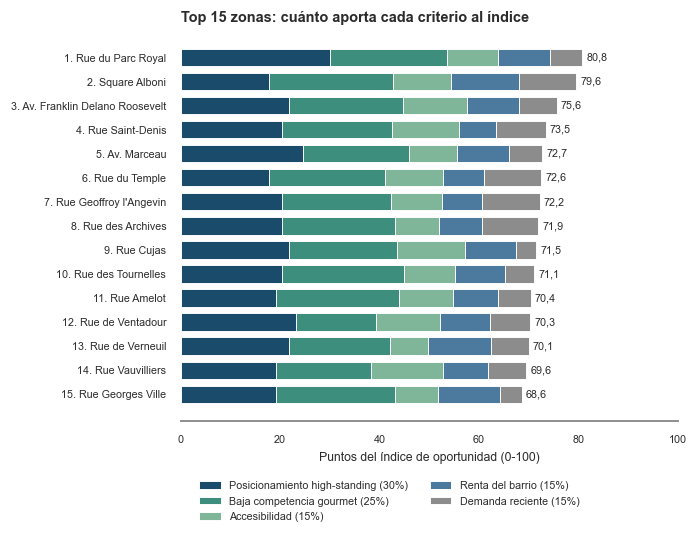

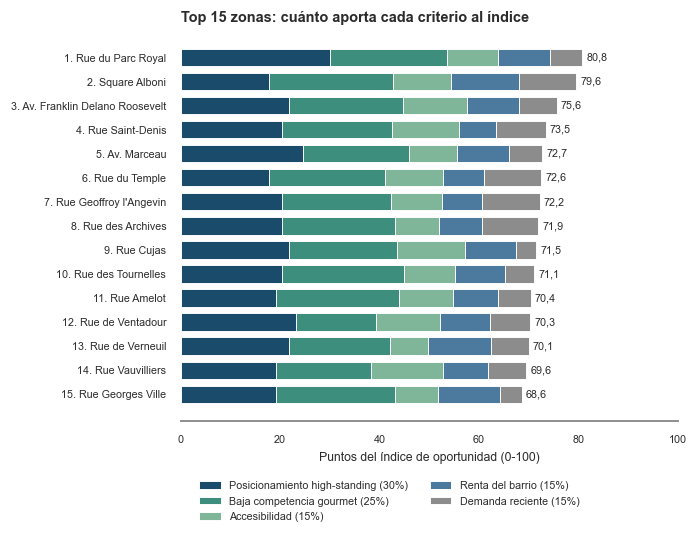

In [32]:
geocoded = pd.read_csv("output/paris_top_zones_geocoded.csv")
plot_opportunity_breakdown(ranked, geocoded, save_path="output/figures/f4_opportunity_breakdown.png")

### Part 3: interactive dashboard

Exports the zone-level results to a self-contained HTML dashboard for the client
(`dashboard/paris_dashboard.html`, built from `dashboard/template.html`). It needs no server or
internet connection: the data is embedded in the page, and the map is drawn from the listings
themselves (no external map tiles).

The client can move the 5 weights of the opportunity index and see the zone ranking and the map
update live, which replaces a fixed sensitivity analysis. The dashboard recomputes the index in the
browser with the same formula as `build_opportunity_index` (MinMax-scaled dimensions, cannibalization
and distance inverted, weights normalised to sum 1), so with `DEFAULT_WEIGHTS` it reproduces the
notebook ranking exactly. Zone outlines are the convex hull of each zone's listings. Addresses exist only for the 15 default top zones; other zones show their Airbnb neighbourhood.

In [33]:
DASHBOARD_TEMPLATE = "dashboard/template.html"
DASHBOARD_OUTPUT = "dashboard/paris_dashboard.html"
DASHBOARD_DATA_PATH = "output/paris_dashboard_data.json"
DASHBOARD_PLACEHOLDER = '"__DASHBOARD_DATA__"'
COORD_DECIMALS = 5          # ~1 m, enough for zone outlines
LISTING_COORD_DECIMALS = 4  # ~10 m, background dots only

# Dashboard dimension key -> (raw column, scaled column)
DASHBOARD_DIMENSIONS = {
    "score": ("highstanding_score_mean", "highstanding_score_mean_scaled"),
    "cannibalization": ("cannibalization_index", "cannibalization_index_scaled"),
    "accessibility": ("dist_to_transit_m", "dist_to_transit_m_scaled"),
    "income": ("income_proxy", "income_proxy_scaled"),
    "demand": ("demand_per_listing", "demand_per_listing_scaled"),
}


def zone_hulls(df_clustered: pd.DataFrame, cluster_col: str) -> dict:
    """Convex hull [(lon, lat), ...] of each zone's listings, used as the zone outline."""
    hulls = {}
    for cid, g in df_clustered[df_clustered[cluster_col] != -1].groupby(cluster_col):
        pts = g[["longitude", "latitude"]].to_numpy()
        hulls[int(cid)] = np.round(pts[ConvexHull(pts).vertices], COORD_DECIMALS).tolist()
    return hulls


def build_dashboard_data(ranked: pd.DataFrame, df_clustered: pd.DataFrame, geocoded: pd.DataFrame,
                         competitors: pd.DataFrame, weights: dict,
                         cluster_col: str = "cluster_hdbscan") -> dict:
    """
    Collects everything the dashboard needs into one JSON-serialisable dict:
    zones (outline, raw and scaled dimensions, default index, neighbourhood,
    address for geocoded zones), background listings, gourmet competitors and
    the default weights.
    """
    hulls = zone_hulls(df_clustered, cluster_col)
    clustered = df_clustered[df_clustered[cluster_col] != -1]
    neighbourhood = clustered.groupby(cluster_col)["neighbourhood"].agg(lambda s: s.mode().iat[0])
    addresses = geocoded.set_index(cluster_col)[["road", "suburb", "postcode"]].fillna("")

    zones = []
    for _, row in ranked.iterrows():
        cid = int(row[cluster_col])
        address = None
        if cid in addresses.index:
            a = addresses.loc[cid]
            address = {"road": a["road"], "district": a["suburb"], "postcode": str(a["postcode"])}
        zones.append({
            "id": cid,
            "n_listings": int(row["n_listings"]),
            "n_competitors": int(row["n_competitors"]),
            "price_median": float(row["price_median"]),
            "lat": round(float(row["centroid_lat"]), COORD_DECIMALS),
            "lon": round(float(row["centroid_lon"]), COORD_DECIMALS),
            "hull": hulls[cid],
            "neighbourhood": neighbourhood[cid],
            "address": address,
            "raw": {k: float(row[raw]) for k, (raw, _) in DASHBOARD_DIMENSIONS.items()},
            "scaled": {k: float(row[sc]) for k, (_, sc) in DASHBOARD_DIMENSIONS.items()},
            "opportunity_index": float(row["opportunity_index"]),
        })

    shortlist_mask = (df_clustered["highstanding_score"] >= SCORE_THRESHOLD).to_numpy()
    listing_coords = np.round(df_clustered[["longitude", "latitude"]].to_numpy(), LISTING_COORD_DECIMALS)
    return {
        "city": city,
        "weights": weights,
        "score_threshold": SCORE_THRESHOLD,
        "zones": zones,
        "listings": listing_coords.ravel().tolist(),
        "shortlist": np.flatnonzero(shortlist_mask).tolist(),
        "competitors": [[round(float(r.longitude), COORD_DECIMALS), round(float(r.latitude), COORD_DECIMALS), r.category]
                        for r in competitors.itertuples()],
    }


def write_dashboard(data: dict, template_path: str = DASHBOARD_TEMPLATE,
                    output_path: str = DASHBOARD_OUTPUT, data_path: str = DASHBOARD_DATA_PATH) -> None:
    """
    Embeds the data into the HTML template and wraps it in a full HTML document,
    giving a single self-contained file that opens in any browser. Saves the JSON too.
    """
    payload = json.dumps(data, ensure_ascii=False, separators=(",", ":"))
    with open(template_path, encoding="utf-8") as f:
        template = f.read()
    assert template.count(DASHBOARD_PLACEHOLDER) == 1, "Template must contain the data placeholder once"
    page = (
        '<!doctype html>\n<html lang="es">\n<head>\n<meta charset="utf-8">\n'
        '<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">\n'
        f'</head>\n<body>\n{template.replace(DASHBOARD_PLACEHOLDER, payload)}\n</body>\n</html>\n'
    )
    with open(output_path, "w", encoding="utf-8") as f:
        f.write(page)
    with open(data_path, "w", encoding="utf-8") as f:
        f.write(payload)
    print(f"[dashboard] {len(data['zones'])} zones, {len(data['listings']) // 2:,} listings, "
          f"{len(data['competitors']):,} competitors -> {output_path} "
          f"({os.path.getsize(output_path) / 1e6:.1f} MB)")


In [34]:
geocoded = pd.read_csv("output/paris_top_zones_geocoded.csv")
dashboard_data = build_dashboard_data(ranked, df_hdbscan, geocoded, competitors_df, DEFAULT_WEIGHTS)
write_dashboard(dashboard_data)


[dashboard] 200 zones, 45,787 listings, 2,069 competitors -> dashboard/paris_dashboard.html (0.9 MB)


---
Supporting functions
---

1. Weight sensibility

In [35]:
N_SAMPLES = 5000
TOP_K = 10
rng = np.random.default_rng(42)

# Dimensiones escaladas (200 zonas x 5), con competencia y distancia ya invertidas
dims = pd.DataFrame({
    "score": ranked["highstanding_score_mean_scaled"],
    "cannibalization": 1 - ranked["cannibalization_index_scaled"],
    "accessibility": 1 - ranked["dist_to_transit_m_scaled"],
    "income": ranked["income_proxy_scaled"],
    "demand": ranked["demand_per_listing_scaled"],
})

# Pesos aleatorios que suman 1 -> índice de cada zona en cada muestra
weights_sim = rng.dirichlet(np.ones(5), size=N_SAMPLES)   # (N_SAMPLES, 5)
index_sim = weights_sim @ dims.values.T                   # (N_SAMPLES, 200)

# Frecuencia con la que cada zona queda en el Top K
top_pos = np.argsort(-index_sim, axis=1)[:, :TOP_K]
freq_topk = np.bincount(top_pos.ravel(), minlength=len(dims)) / N_SAMPLES

robustness = ranked.assign(freq_top10=freq_topk)
print(robustness[["cluster_hdbscan", "opportunity_index", "freq_top10"]]
      .head(15).round(2).to_string(index=False))

 cluster_hdbscan  opportunity_index  freq_top10
             168              80.77        0.60
              15              79.57        0.93
              20              75.62        0.73
             181              73.46        0.55
              17              72.74        0.25
             188              72.57        0.52
             179              72.22        0.43
             186              71.94        0.41
              54              71.49        0.35
             129              71.09        0.17
             128              70.39        0.15
              47              70.29        0.31
              22              70.05        0.26
             110              69.56        0.29
              12              68.64        0.18


2. Competence radius sensibility

In [36]:
RADII = [300, 400, 500]

top15_by_radius = {}
for r in RADII:
    tmp = compute_competition_metrics(competitors_df, df_scored, full, radius_m=r)
    top15_by_radius[r] = set(build_opportunity_index(tmp).head(15)["cluster_hdbscan"])

base = top15_by_radius[400]
for r in RADII:
    common = len(base & top15_by_radius[r])
    print(f"Radio {r} m: {common}/15 zonas en común con el Top 15 base")

Radio 300 m: 13/15 zonas en común con el Top 15 base
Radio 400 m: 15/15 zonas en común con el Top 15 base
Radio 500 m: 13/15 zonas en común con el Top 15 base
